# Final Project: Exploratory Data Analysis

## Project Information

**Project Title:** Predicting Obesity Rates: The Impact of Processed Foods and Controllable Dietary Variables

**Team Members:**
- Srivats Pulumati (srp159@pitt.edu)
- Nischal Kharel (nik174@pitt.edu)
- Fernando Seanez (fes35@pitt.edu)

**Research Question:** 

How much do processed foods and other controllable dietary variables (fat consumption, sugar intake, protein consumption, total caloric availability) contribute to obesity rates, and how drastically could changing these variables affect the obesity rate?

**Why is this research question interesting to our team:**

Food is an essential part of everyone's daily life, yet many people don't fully understand the health consequences of consuming processed foods and the chemicals they contain. We're interested in this question because obesity is a major public health crisis affecting millions worldwide, and understanding the specific dietary factors that contribute to it could help us identify concrete, actionable interventions. Unlike genetic or environmental factors that are hard to control, dietary variables like processed food consumption, fat intake, and sugar consumption are modifiable at both individual and policy levels. If we can quantify exactly how much each factor contributes to obesity, we can provide evidence-based recommendations for reducing obesity rates.

**Why we consider this project useful:**

This project has real-world applications that could benefit multiple stakeholders:

1. **For policymakers:** Our model will provide data-driven evidence to support public health policies, such as regulations on processed foods, sugar taxes, or nutritional labeling requirements.

2. **For health organizations:** By identifying which dietary factors have the strongest relationship with obesity, health organizations can focus their educational campaigns and interventions on the most impactful areas.

3. **For individuals:** People making dietary choices will understand which changes have the biggest impact on obesity risk, helping them prioritize their efforts.

4. **For researchers:** Our findings can guide future research into dietary interventions and obesity prevention strategies.

The predictive component of our model is particularly useful because it allows us to answer "what-if" questions: "If we reduce sugar consumption by 10%, how much would obesity rates decrease?" This type of scenario analysis is invaluable for policy planning.

**Who would benefit from our model:**
- Public health officials designing obesity prevention programs
- Nutritionists and dietitians counseling patients
- Policy advocates pushing for healthier food regulations
- Individuals wanting to make informed dietary decisions
- Researchers studying nutrition and public health
- Food industry stakeholders interested in product reformulation

## 1. Data Sources and Feature Descriptions

### Data Sources:

We obtained our data from the following authoritative international sources:

1. **WHO Global Health Observatory - Obesity Prevalence Dataset**
   - Source: World Health Organization (WHO)
   - File: `Prevalence_of_obesity_among_adults_WHO.csv`
   - Contains: Obesity prevalence rates by country, year, sex, and age group
   - This is our **response variable**

2. **FAO Food Balance Sheets**
   - Source: Food and Agriculture Organization (FAO) of the United Nations
   - File: `FoodBalanceSheets_E_All_Area_Groups.csv`
   - Contains: Comprehensive food supply data including calories, protein, fat, and food category availability
   - This provides our **predictor variables**

3. **Daily Per Capita Fat Supply**
   - Source: FAO via Our World in Data
   - File: `daily-per-capita-fat-supply.csv`
   - Contains: Daily fat consumption in grams per capita by country and year
   - This is a key **predictor variable**

### Feature Descriptions:

#### Response Variable (What we're trying to predict):
- **Obesity_Rate**: Percentage of adults (18+) with BMI ≥ 30 in a given country and year

#### Predictor Variables (What we'll use to predict obesity):

1. **Fat_Supply_g_per_capita**: Daily per capita fat supply in grams
   - Represents total fat availability in the food supply
   - Higher fat consumption is hypothesized to correlate with higher obesity

2. **Calories_kcal_per_capita**: Daily per capita caloric supply in kilocalories
   - Total energy available from all food sources
   - Excess calorie consumption leads to weight gain

3. **Protein_g_per_capita**: Daily per capita protein supply in grams
   - Total protein availability from all sources
   - Can indicate diet quality and food system development

4. **Sugar_Sweeteners_g_per_capita**: Daily per capita sugar and sweetener consumption in grams
   - Includes refined sugars and artificial sweeteners
   - High sugar consumption is strongly linked to obesity

5. **Processed_Foods_Index**: Proportion of calories from processed/ultra-processed foods
   - Derived from food balance sheet categories
   - Processed foods are typically calorie-dense and nutrient-poor

6. **Year**: Year of observation (2010-2023)
   - Captures temporal trends in obesity and food supply

7. **Country**: Country name
   - Will be encoded for modeling to capture geographic/cultural effects

In [1]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import skew, kurtosis, pearsonr
import warnings
warnings.filterwarnings('ignore')

# set up visualization style
sns.set_style('whitegrid')
sns.set_palette('husl')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [2]:
# load datasets
import os

# adjust paths as needed
who_obesity = pd.read_csv('./Datasets/Prevalence_of_obesity_among_adults_WHO.csv')
fat_supply = pd.read_csv('./Datasets/daily-per-capita-fat-supply.csv')
food_balance = pd.read_csv('./Datasets/FoodBalanceSheets_E_All_Data.csv', encoding='latin-1')


print("WHO Obesity data shape:", who_obesity.shape)
print("Fat supply data shape:", fat_supply.shape)
print("Food balance data shape:", food_balance.shape)
print("\nDatasets loaded successfully!")

WHO Obesity data shape: (19701, 34)
Fat supply data shape: (12817, 4)
Food balance data shape: (373670, 51)

Datasets loaded successfully!


## 2. Initial Data Exploration

In [3]:
# look at WHO obesity data structure
print("WHO Obesity Dataset - First 5 rows:")
print(who_obesity.head())
print("\nColumn names:")
print(who_obesity.columns.tolist())

WHO Obesity Dataset - First 5 rows:
  IndicatorCode                                          Indicator ValueType  \
0   NCD_BMI_30A  Prevalence of obesity among adults, BMI &Great...   numeric   
1   NCD_BMI_30A  Prevalence of obesity among adults, BMI &Great...   numeric   
2   NCD_BMI_30A  Prevalence of obesity among adults, BMI &Great...   numeric   
3   NCD_BMI_30A  Prevalence of obesity among adults, BMI &Great...   numeric   
4   NCD_BMI_30A  Prevalence of obesity among adults, BMI &Great...   numeric   

  ParentLocationCode         ParentLocation Location type SpatialDimValueCode  \
0                AFR                 Africa       Country                 ETH   
1               SEAR        South-East Asia       Country                 TLS   
2                AFR                 Africa       Country                 RWA   
3                WPR        Western Pacific       Country                 VNM   
4                EMR  Eastern Mediterranean       Country                 YEM 

In [4]:
# check the key columns we need
print("Unique countries:", who_obesity['Location'].nunique())
print("Year range:", who_obesity['Period'].min(), "-", who_obesity['Period'].max())


print("\nSex categories:")
print(who_obesity['Dim1'].value_counts())


print("\nAge categories:")
print(who_obesity['Dim2'].value_counts())

Unique countries: 199
Year range: 1990 - 2022

Sex categories:
Dim1
Male          6567
Female        6567
Both sexes    6567
Name: count, dtype: int64

Age categories:
Dim2
18+  years    19701
Name: count, dtype: int64


We have 199 Unique Countries for this who_obesity dataset.

We have an equal number of males and females

We have over 19,000 subjects who are 18+

In [5]:
# look at fat supply data
print("Fat Supply Dataset:")
print(fat_supply.head())

print("\nColumns:")
print(fat_supply.columns.tolist())

Fat Supply Dataset:
        Entity Code  Year  \
0  Afghanistan  AFG  1961   
1  Afghanistan  AFG  1962   
2  Afghanistan  AFG  1963   
3  Afghanistan  AFG  1964   
4  Afghanistan  AFG  1965   

   total__00002901__food_available_for_consumption__0684pc__grams_of_fat_per_day_per_capita  
0                                          36.451218                                         
1                                          36.560574                                         
2                                          37.507850                                         
3                                          37.889103                                         
4                                          38.657166                                         

Columns:
['Entity', 'Code', 'Year', 'total__00002901__food_available_for_consumption__0684pc__grams_of_fat_per_day_per_capita']


### Our fat_supply dataset contains Countries, Year, and "pc_grams_of_fat_per_day_per_capita"

In [6]:
# look at food balance sheet structure
print("Food Balance Sheets - Sample:")
print(food_balance.head())

Food Balance Sheets - Sample:
   Area Code Area Code (M49)         Area  Item Code Item Code (FBS)  \
0          2            '004  Afghanistan       2501          'S2501   
1          2            '004  Afghanistan       2901          'S2901   
2          2            '004  Afghanistan       2901          'S2901   
3          2            '004  Afghanistan       2901          'S2901   
4          2            '004  Afghanistan       2901          'S2901   

          Item  Element Code                                 Element  \
0   Population           511           Total Population - Both sexes   
1  Grand Total           664           Food supply (kcal/capita/day)   
2  Grand Total           661                      Food supply (kcal)   
3  Grand Total           674  Protein supply quantity (g/capita/day)   
4  Grand Total           671             Protein supply quantity (t)   

           Unit        Y2010  ... Y2020N        Y2021  Y2021F Y2021N  \
0       1000 No     28284.09  ..

In [7]:
print("\nUnique food items:")
print(food_balance['Item'].unique()[:20])  # show first 20

print(f"\nTotal unique items: {food_balance['Item'].nunique()}")

print("\nElement types:")
print(food_balance['Element'].unique())


Unique food items:
['Population' 'Grand Total' 'Vegetal Products' 'Animal Products'
 'Cereals - Excluding Beer' 'Wheat and products' 'Rice and products'
 'Barley and products' 'Maize and products' 'Rye and products' 'Oats'
 'Millet and products' 'Sorghum and products' 'Cereals, other'
 'Starchy Roots' 'Cassava and products' 'Potatoes and products'
 'Sweet potatoes' 'Yams' 'Roots, Other']

Total unique items: 120

Element types:
['Total Population - Both sexes' 'Food supply (kcal/capita/day)'
 'Food supply (kcal)' 'Protein supply quantity (g/capita/day)'
 'Protein supply quantity (t)' 'Fat supply quantity (g/capita/day)'
 'Fat supply quantity (t)' 'Production' 'Import quantity'
 'Stock Variation' 'Export quantity' 'Domestic supply quantity' 'Feed'
 'Seed' 'Losses' 'Processing' 'Other uses (non-food)' 'Residuals' 'Food'
 'Food supply quantity (kg/capita/yr)' 'Tourist consumption']


## 3. Data Cleaning

### 3.1 Dealing with Missing Values

#### 3.1.1 Visualizing Missing Values

MISSING VALUES ANALYSIS: WHO OBESITY DATA
                            Missing_Count  Percentage
FactValueNumericLowPrefix           19701       100.0
Dim3 type                           19701       100.0
FactValueNumericHighPrefix          19701       100.0
Dim3                                19701       100.0
FactValueUoM                        19701       100.0
FactValueNumericPrefix              19701       100.0
DataSource                          19701       100.0
DataSourceDimValueCode              19701       100.0
FactValueTranslationID              19701       100.0
FactComments                        19701       100.0
Dim3ValueCode                       19701       100.0


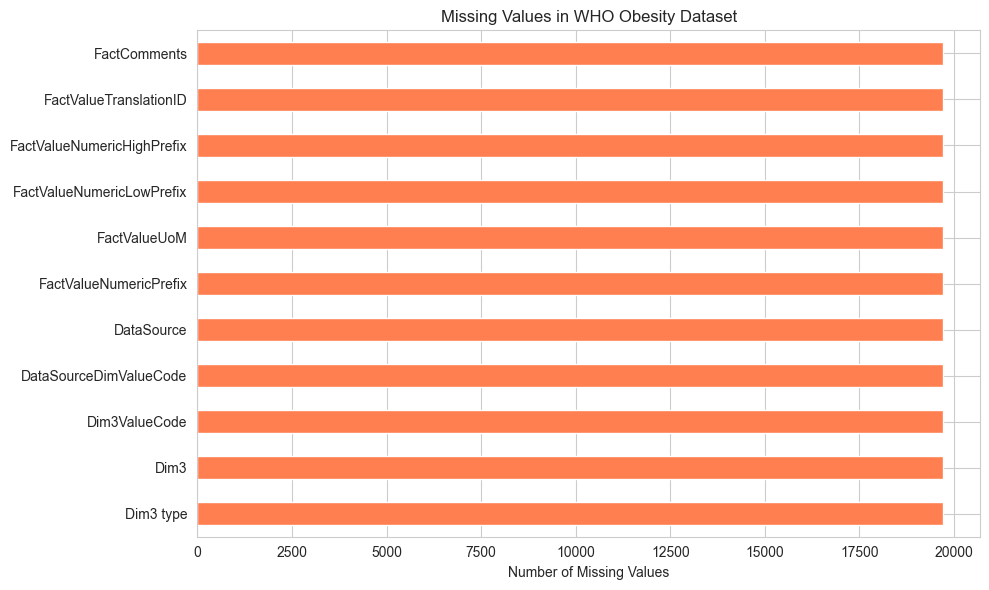

In [8]:
# check missing values in WHO obesity data
print("MISSING VALUES ANALYSIS: WHO OBESITY DATA")

missing_who = who_obesity.isnull().sum()
missing_who_pct = (missing_who / len(who_obesity)) * 100

missing_df = pd.DataFrame({
    'Missing_Count': missing_who,
    'Percentage': missing_who_pct
}).sort_values('Missing_Count', ascending=False)

print(missing_df[missing_df['Missing_Count'] > 0])

# visualize
if missing_who.sum() > 0:
    top_missing = missing_who[missing_who > 0].head(15)
    plt.figure(figsize=(10, 6))
    top_missing.plot(kind='barh', color='coral')
    plt.xlabel('Number of Missing Values')
    plt.title('Missing Values in WHO Obesity Dataset')
    plt.tight_layout()
    plt.show()
else:
    print("\nNo missing values in key columns!")

#### From the above we can see that the columns above are missing 100% of their data, therefore we can get rid of them

In [9]:
# check missing values in fat supply
print("MISSING VALUES ANALYSIS: FAT SUPPLY DATA")


missing_fat = fat_supply.isnull().sum()
print(missing_fat)
print(f"\nPercentage missing:")
print((missing_fat / len(fat_supply)) * 100)

MISSING VALUES ANALYSIS: FAT SUPPLY DATA
Entity                                                                                         0
Code                                                                                        2601
Year                                                                                           0
total__00002901__food_available_for_consumption__0684pc__grams_of_fat_per_day_per_capita       0
dtype: int64

Percentage missing:
Entity                                                                                       0.00000
Code                                                                                        20.29336
Year                                                                                         0.00000
total__00002901__food_available_for_consumption__0684pc__grams_of_fat_per_day_per_capita     0.00000
dtype: float64


### From the above, I can see that around 20% of the "Code" Data is missing from the dataset. However, after revieweing the overall dataset, the "Code" section is irrelevant for our purposes as it is just an abbreviation of whatever is in "Entity" in that row

MISSING VALUES ANALYSIS: FOOD BALANCE SHEETS
Top 20 columns with missing values:
Y2010N    373670
Y2012N    373670
Y2011N    373670
Y2018N    373670
Y2019N    373670
Y2020N    373670
Y2017N    373670
Y2016N    373670
Y2023N    373670
Y2022N    373670
Y2021N    373670
Y2014N    373670
Y2015N    373670
Y2013N    373670
Y2010F     34084
Y2010      34084
Y2011F     33881
Y2011      33881
Y2012F     33257
Y2012      33257
dtype: int64


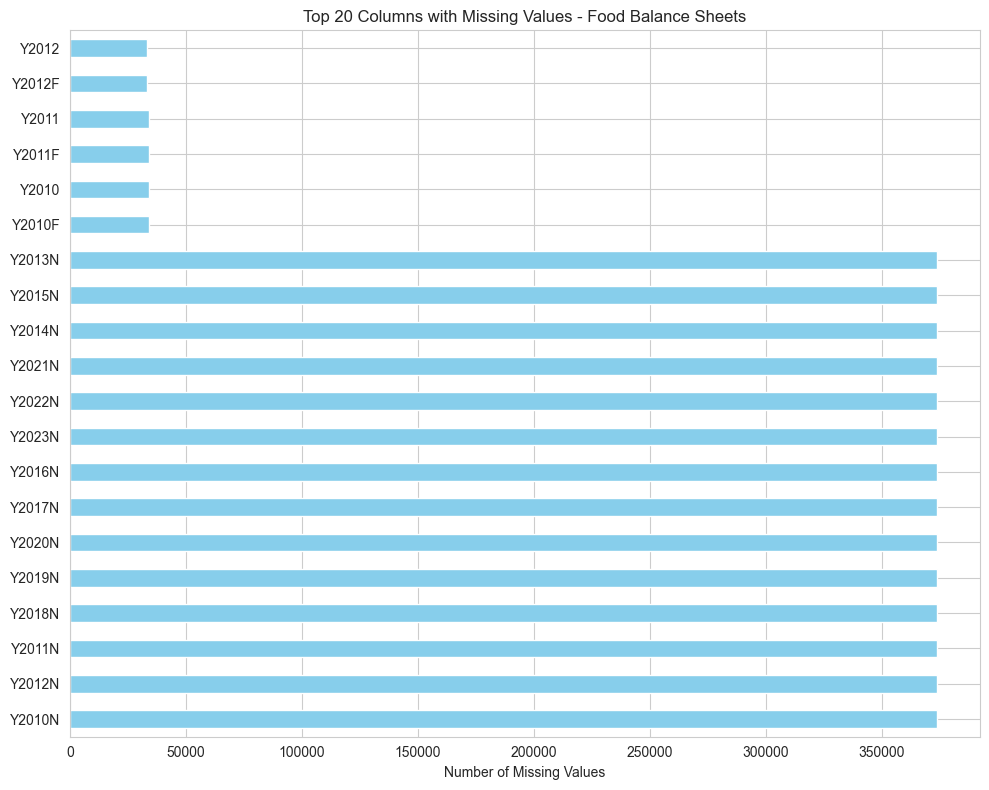

In [10]:
# check missing values in food balance sheets
print("MISSING VALUES ANALYSIS: FOOD BALANCE SHEETS")

missing_food = food_balance.isnull().sum().sort_values(ascending=False)
print("Top 20 columns with missing values:")
print(missing_food.head(20))

# visualize
plt.figure(figsize=(10, 8))
missing_food.head(20).plot(kind='barh', color='skyblue')
plt.xlabel('Number of Missing Values')
plt.title('Top 20 Columns with Missing Values - Food Balance Sheets')
plt.tight_layout()
plt.show()

## From the above, we can see that we are missing a lot of rows for the years from 2011-2023 (almost 70,000)

#### 3.1.2 Addressing Missing Values

**Strategy:**

1. **WHO Obesity Data:** Most missing values are in metadata columns (Dim3, DataSource, etc.) that we don't need. We'll drop these columns and keep only the essential obesity rate data.

2. **Fat Supply Data:** Remove rows without country codes (regional aggregates) and without actual fat supply values.

3. **Food Balance Sheets:** Drop flag (F) and notes (N) columns as they're metadata. For rows with >50% missing year data, we'll remove them as they won't provide reliable trends.

In [11]:
# clean WHO obesity data
print("Cleaning WHO Obesity Data...")
print(f"Original shape: {who_obesity.shape}")

# keep only the columns we need
who_clean = who_obesity[[
    'Location',          # Country
    'Period',            # Year
    'Dim1',              # Sex
    'Dim2',              # Age group
    'FactValueNumeric',  # Obesity rate
    'FactValueNumericLow',  # Lower confidence interval
    'FactValueNumericHigh'  # Upper confidence interval
]].copy()

# rename for clarity
who_clean.columns = ['Country', 'Year', 'Sex', 'Age_Group', 'Obesity_Rate', 
                      'Obesity_Rate_Low', 'Obesity_Rate_High']

print(f"Cleaned shape: {who_clean.shape}")
print(" WHO obesity data cleaned!\n")

Cleaning WHO Obesity Data...
Original shape: (19701, 34)
Cleaned shape: (19701, 7)
 WHO obesity data cleaned!



In [12]:
# clean fat supply data
print("Cleaning Fat Supply Data...")
print(f"Original shape: {fat_supply.shape}")

fat_clean = fat_supply.copy()

# rename that ridiculous column name
fat_clean.columns = ['Entity', 'Code', 'Year', 'Fat_Supply']

# drop rows without country codes or fat values
initial_len = len(fat_clean)
fat_clean = fat_clean.dropna(subset=['Code', 'Fat_Supply'])
print(f"Removed {initial_len - len(fat_clean)} rows with missing values")

# rename Entity to Country for consistency
fat_clean = fat_clean.rename(columns={'Entity': 'Country'})

print(f"Cleaned shape: {fat_clean.shape}")
print(" Fat supply data cleaned!\n")

Cleaning Fat Supply Data...
Original shape: (12817, 4)
Removed 2601 rows with missing values
Cleaned shape: (10216, 4)
 Fat supply data cleaned!



In [13]:
# clean food balance sheets
print("Cleaning Food Balance Sheets...")
print(f"Original shape: {food_balance.shape}")

food_clean = food_balance.copy()

# drop flag and note columns
flag_note_cols = [col for col in food_clean.columns if col.endswith('F') or col.endswith('N')]
print(f"Dropping {len(flag_note_cols)} metadata columns")
food_clean = food_clean.drop(columns=flag_note_cols)

# drop rows with >50% missing year data
year_cols = [col for col in food_clean.columns if col.startswith('Y')]
missing_pct_per_row = food_clean[year_cols].isnull().sum(axis=1) / len(year_cols)
initial_len = len(food_clean)
food_clean = food_clean[missing_pct_per_row <= 0.5]
print(f"Removed {initial_len - len(food_clean)} rows with >50% missing year data")

print(f"Cleaned shape: {food_clean.shape}")
print(" Food balance sheets cleaned!\n")

# MUST CHANGE THE AREA COEDS TO COUNTRY NAMES!

Cleaning Food Balance Sheets...
Original shape: (373670, 51)
Dropping 28 metadata columns
Removed 31535 rows with >50% missing year data
Cleaned shape: (342135, 23)
 Food balance sheets cleaned!



#### 3.1.3 Justification for Missing Value Approach

**WHO Obesity Data:**
We removed many metadata columns that were entirely empty (like Dim3, DataSource, FactComments). These columns don't contain information relevant to our analysis. We kept only the essential variables: country, year, demographic information (sex, age), and the actual obesity rates with confidence intervals.

**Fat Supply Data:**
Rows without country codes represent regional or global aggregates (like "World" or "Africa") that don't match our country-level analysis. Rows without fat supply values are useless for prediction since fat consumption is one of our key predictors. Removing these rows maintains data quality without significant information loss.

**Food Balance Sheets:**
The F (flag) and N (notes) columns are metadata about data collection methods, not actual measurements. Rows with >50% missing year data lack temporal continuity needed for trend analysis. We chose 50% as the threshold because it allows some missing data while ensuring enough years are present for meaningful analysis.

### 3.2 Dealing with Outliers

#### 3.2.1 Visualizing Outliers

OUTLIER ANALYSIS: OBESITY RATES


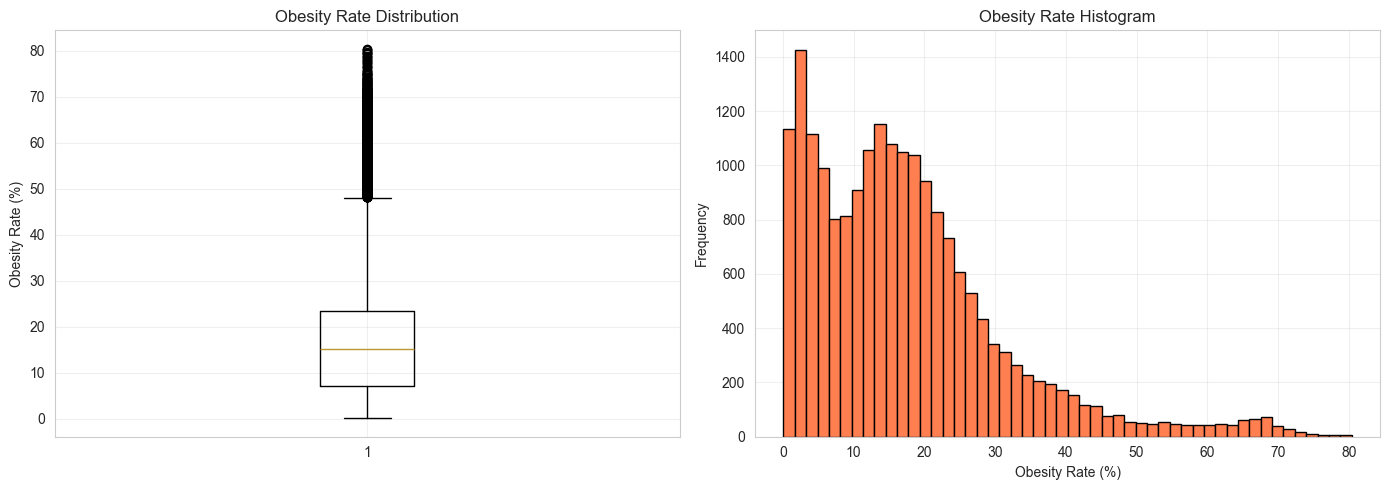


Q1: 7.01%
Q3: 23.44%
IQR: 16.43
Lower bound: -17.63%
Upper bound: 48.09%

Number of outliers: 805 (4.09%)

Examples of high obesity outliers:
             Country  Year     Sex   Age_Group  Obesity_Rate
581   American Samoa  2022  Female  18+  years         80.39
1179  American Samoa  2021  Female  18+  years         80.11
580            Tonga  2022  Female  18+  years         80.09
1766  American Samoa  2020  Female  18+  years         79.81
2361  American Samoa  2019  Female  18+  years         79.51
1161           Tonga  2021  Female  18+  years         79.40
2953  American Samoa  2018  Female  18+  years         79.19
3549  American Samoa  2017  Female  18+  years         78.86
1765           Tonga  2020  Female  18+  years         78.69
4148  American Samoa  2016  Female  18+  years         78.52


In [14]:
# analyze obesity rate outliers
print("OUTLIER ANALYSIS: OBESITY RATES")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# box plot
axes[0].boxplot(who_clean['Obesity_Rate'])
axes[0].set_ylabel('Obesity Rate (%)')
axes[0].set_title('Obesity Rate Distribution')
axes[0].grid(True, alpha=0.3)

# histogram
axes[1].hist(who_clean['Obesity_Rate'], bins=50, edgecolor='black', color='coral')
axes[1].set_xlabel('Obesity Rate (%)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Obesity Rate Histogram')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# calculate IQR
Q1 = who_clean['Obesity_Rate'].quantile(0.25)
Q3 = who_clean['Obesity_Rate'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = who_clean[(who_clean['Obesity_Rate'] < lower_bound) | 
                      (who_clean['Obesity_Rate'] > upper_bound)]

print(f"\nQ1: {Q1:.2f}%")
print(f"Q3: {Q3:.2f}%")
print(f"IQR: {IQR:.2f}")
print(f"Lower bound: {lower_bound:.2f}%")
print(f"Upper bound: {upper_bound:.2f}%")
print(f"\nNumber of outliers: {len(outliers)} ({len(outliers)/len(who_clean)*100:.2f}%)")

# show some examples of outliers
print("\nExamples of high obesity outliers:")
high_outliers = who_clean[who_clean['Obesity_Rate'] > upper_bound].nlargest(10, 'Obesity_Rate')
print(high_outliers[['Country', 'Year', 'Sex', 'Age_Group', 'Obesity_Rate']])

OUTLIER ANALYSIS: FAT SUPPLY


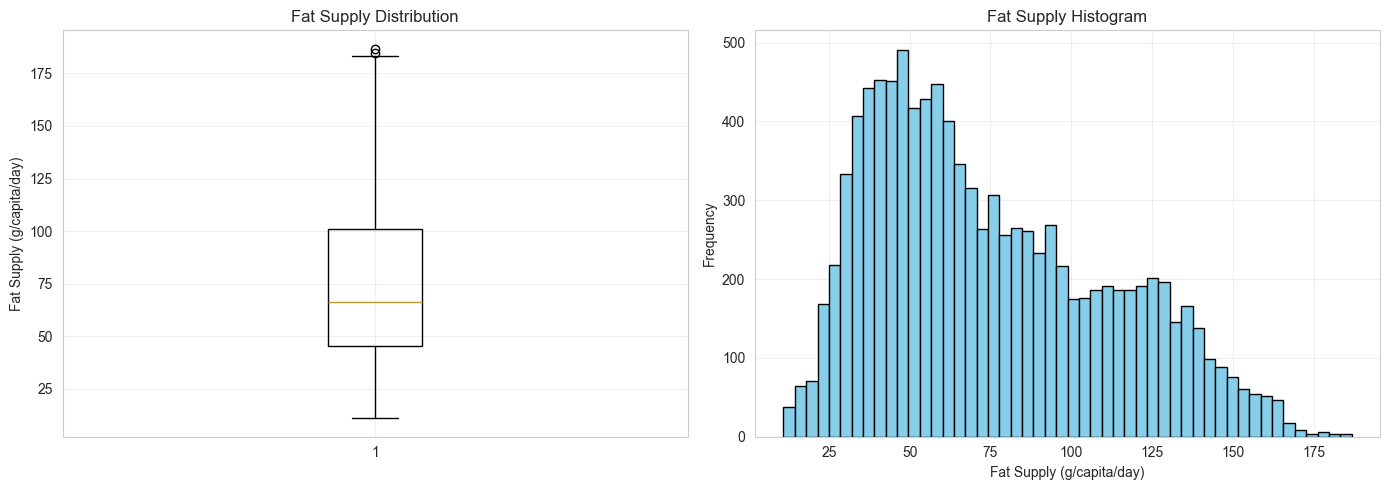


Outliers: 2 (0.02%)

Descriptive statistics:
count    10216.000000
mean        74.780878
std         36.303513
min         10.974196
25%         45.412312
50%         66.454955
75%        100.884033
max        186.676070
Name: Fat_Supply, dtype: float64


In [15]:
# analyze fat supply outliers
print("OUTLIER ANALYSIS: FAT SUPPLY")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# box plot
axes[0].boxplot(fat_clean['Fat_Supply'])
axes[0].set_ylabel('Fat Supply (g/capita/day)')
axes[0].set_title('Fat Supply Distribution')
axes[0].grid(True, alpha=0.3)

# histogram
axes[1].hist(fat_clean['Fat_Supply'], bins=50, edgecolor='black', color='skyblue')
axes[1].set_xlabel('Fat Supply (g/capita/day)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Fat Supply Histogram')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# calculate IQR
Q1_fat = fat_clean['Fat_Supply'].quantile(0.25)
Q3_fat = fat_clean['Fat_Supply'].quantile(0.75)
IQR_fat = Q3_fat - Q1_fat
lower_fat = Q1_fat - 1.5 * IQR_fat
upper_fat = Q3_fat + 1.5 * IQR_fat

outliers_fat = fat_clean[(fat_clean['Fat_Supply'] < lower_fat) | 
                         (fat_clean['Fat_Supply'] > upper_fat)]

print(f"\nOutliers: {len(outliers_fat)} ({len(outliers_fat)/len(fat_clean)*100:.2f}%)")
print(f"\nDescriptive statistics:")
print(fat_clean['Fat_Supply'].describe())

#### 3.2.2 Addressing Outliers

**Decision: Keep all outliers**

We're keeping the outliers for several important reasons:

1. **They represent real phenomena:** The outliers in obesity rates (countries with very high or very low obesity) and fat consumption are genuine data points, not measurement errors. For example, some Pacific island nations genuinely have obesity rates above 50%, while some developing nations have rates below 5%.

2. **Research relevance:** Our research question specifically aims to understand the full spectrum of relationships between diet and obesity. Extreme cases provide valuable information about these relationships at the tails of the distribution.

3. **Predictive value:** For a predictive model, we want to be able to make accurate predictions for all types of countries, not just "average" ones. Removing outliers would limit our model's applicability.

4. **Policy implications:** The countries with extreme obesity rates are often the ones most in need of interventions. Our model should work for them too.

5. **Statistical robustness:** We plan to use tree-based models (Random Forest, Gradient Boosting) which are naturally robust to outliers, so we don't need to remove them for model performance.

In [16]:
# flag outliers for reference but keep them
fat_clean['is_outlier_fat'] = ((fat_clean['Fat_Supply'] < lower_fat) | 
                                (fat_clean['Fat_Supply'] > upper_fat))

print(f"Flagged {fat_clean['is_outlier_fat'].sum()} outliers in fat supply")
print("All data points retained for analysis")

Flagged 2 outliers in fat supply
All data points retained for analysis


### 3.3 Evaluating Distributions

#### 3.3.1 Visualizing Distributions

DISTRIBUTION ANALYSIS: OBESITY RATES


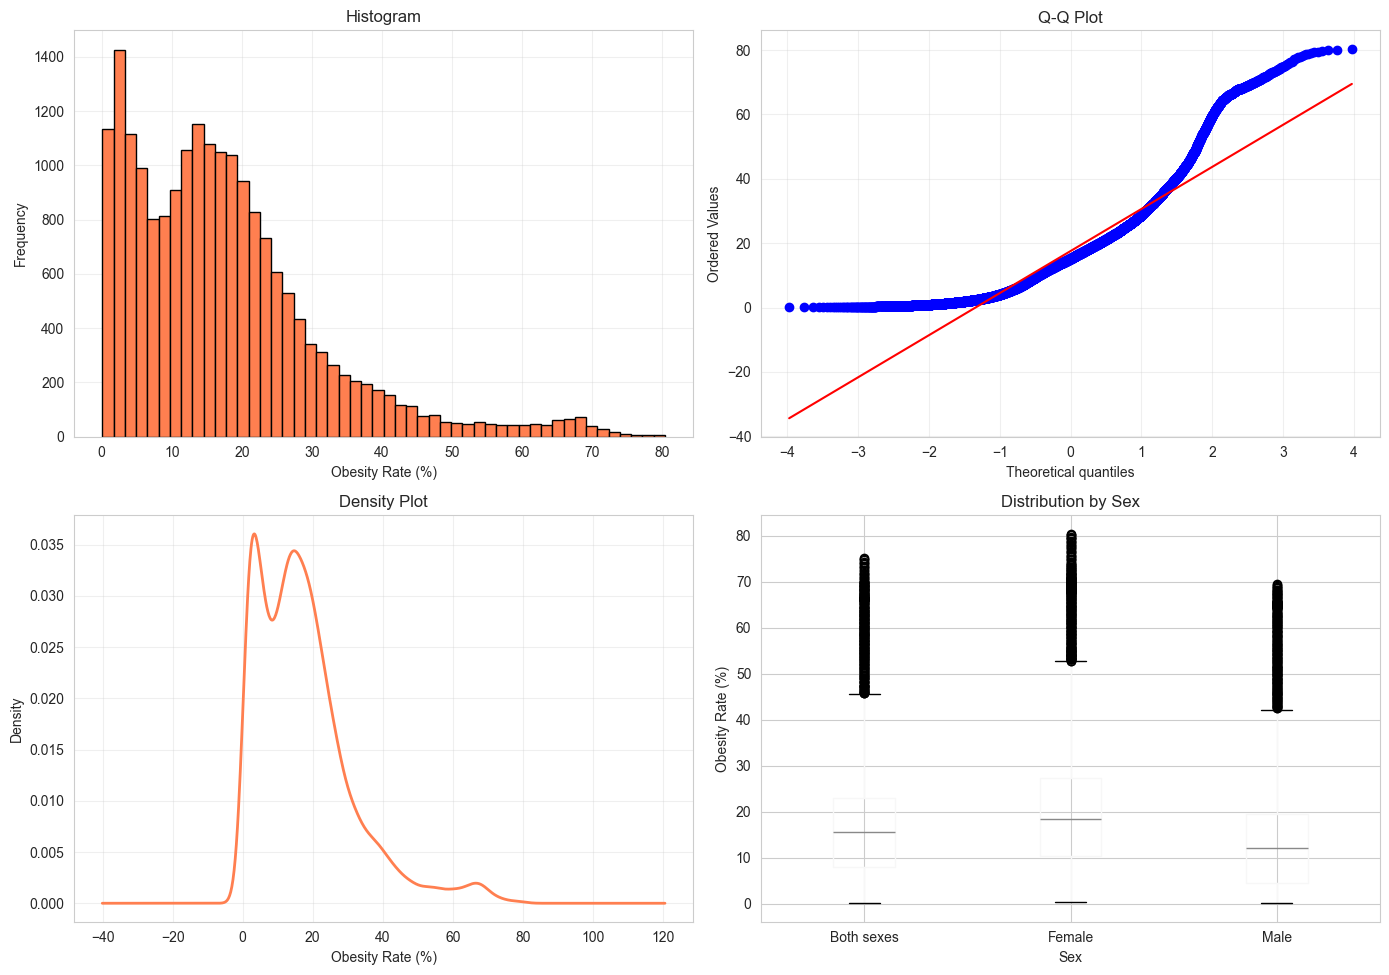


Skewness: 1.423
Kurtosis: 2.564
Interpretation: Distribution is right-skewed (positive skew)


In [17]:
# analyze obesity rate distribution
print("DISTRIBUTION ANALYSIS: OBESITY RATES")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# histogram
axes[0, 0].hist(who_clean['Obesity_Rate'], bins=50, edgecolor='black', color='coral')
axes[0, 0].set_xlabel('Obesity Rate (%)')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Histogram')
axes[0, 0].grid(True, alpha=0.3)

# Q-Q plot
stats.probplot(who_clean['Obesity_Rate'], dist="norm", plot=axes[0, 1])
axes[0, 1].set_title('Q-Q Plot')
axes[0, 1].grid(True, alpha=0.3)

# density plot
who_clean['Obesity_Rate'].plot(kind='density', ax=axes[1, 0], color='coral', linewidth=2)
axes[1, 0].set_xlabel('Obesity Rate (%)')
axes[1, 0].set_title('Density Plot')
axes[1, 0].grid(True, alpha=0.3)

# box plot by sex
who_clean.boxplot(column='Obesity_Rate', by='Sex', ax=axes[1, 1])
axes[1, 1].set_xlabel('Sex')
axes[1, 1].set_ylabel('Obesity Rate (%)')
axes[1, 1].set_title('Distribution by Sex')
plt.suptitle('')

plt.tight_layout()
plt.show()

# calculate skewness and kurtosis
obesity_skew = skew(who_clean['Obesity_Rate'])
obesity_kurt = kurtosis(who_clean['Obesity_Rate'])

print(f"\nSkewness: {obesity_skew:.3f}")
print(f"Kurtosis: {obesity_kurt:.3f}")

if abs(obesity_skew) < 0.5:
    print("Interpretation: Distribution is approximately symmetric")
elif obesity_skew > 0:
    print("Interpretation: Distribution is right-skewed (positive skew)")
else:
    print("Interpretation: Distribution is left-skewed (negative skew)")

DISTRIBUTION ANALYSIS: FAT SUPPLY


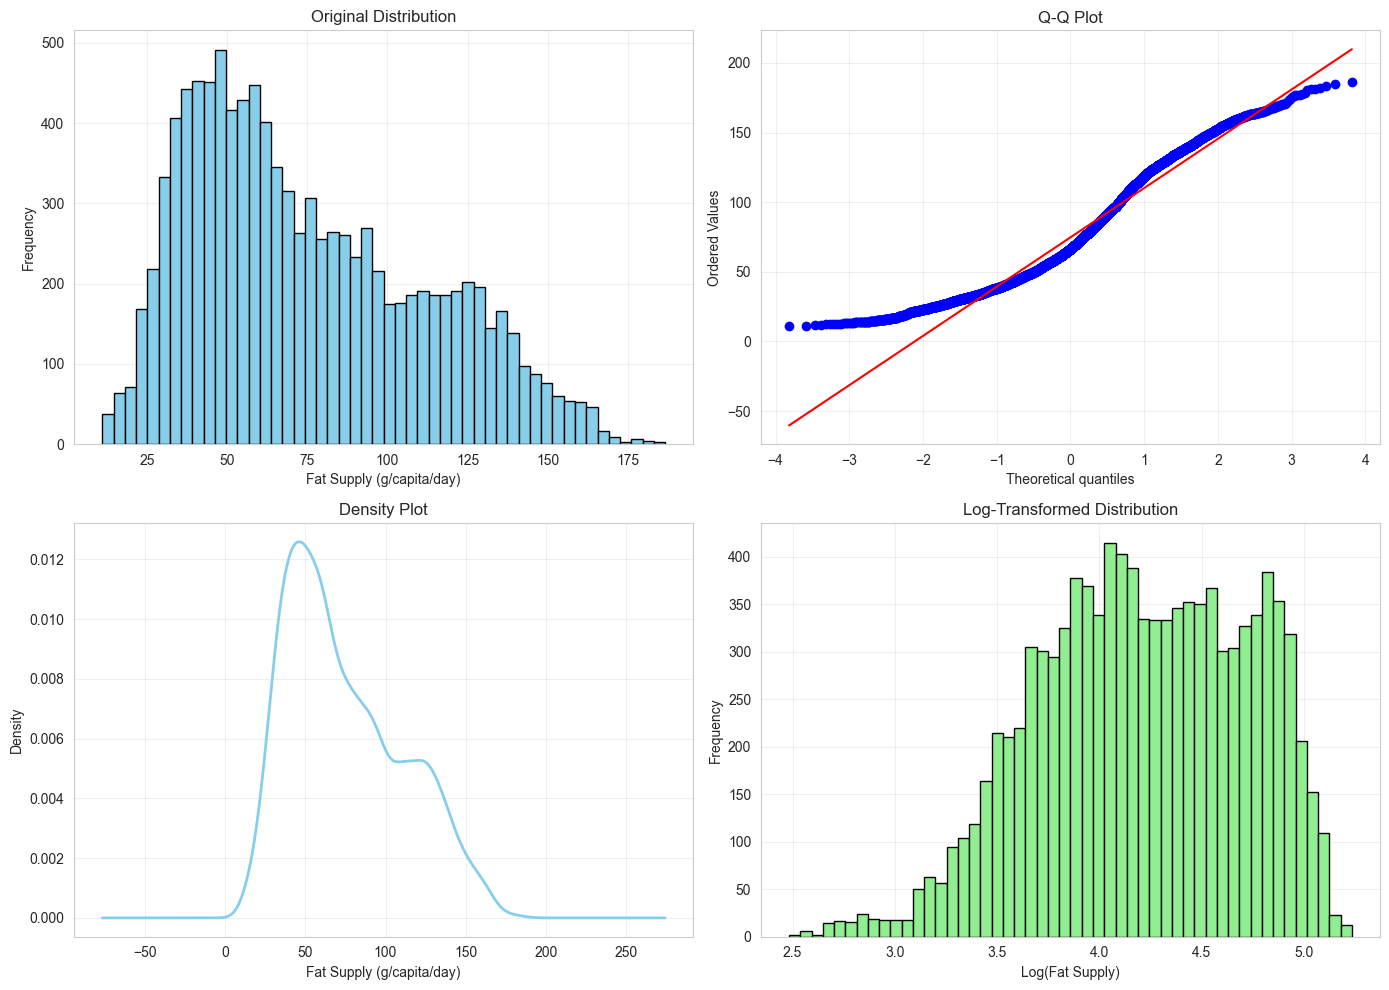


Original skewness: 0.571
Log-transformed skewness: -0.290
Improvement from log transformation: 0.281


In [18]:
# analyze fat supply distribution
print("DISTRIBUTION ANALYSIS: FAT SUPPLY")


fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# original distribution
axes[0, 0].hist(fat_clean['Fat_Supply'], bins=50, edgecolor='black', color='skyblue')
axes[0, 0].set_xlabel('Fat Supply (g/capita/day)')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Original Distribution')
axes[0, 0].grid(True, alpha=0.3)

# Q-Q plot
stats.probplot(fat_clean['Fat_Supply'], dist="norm", plot=axes[0, 1])
axes[0, 1].set_title('Q-Q Plot')
axes[0, 1].grid(True, alpha=0.3)

# density
fat_clean['Fat_Supply'].plot(kind='density', ax=axes[1, 0], color='skyblue', linewidth=2)
axes[1, 0].set_xlabel('Fat Supply (g/capita/day)')
axes[1, 0].set_title('Density Plot')
axes[1, 0].grid(True, alpha=0.3)
# log-transformed version
log_fat = np.log1p(fat_clean['Fat_Supply'])
axes[1, 1].hist(log_fat, bins=50, edgecolor='black', color='lightgreen')
axes[1, 1].set_xlabel('Log(Fat Supply)')
axes[1, 1].set_ylabel('Frequency')
axes[1, 1].set_title('Log-Transformed Distribution')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

fat_skew = skew(fat_clean['Fat_Supply'])
log_fat_skew = skew(log_fat)

print(f"\nOriginal skewness: {fat_skew:.3f}")
print(f"Log-transformed skewness: {log_fat_skew:.3f}")
print(f"Improvement from log transformation: {abs(fat_skew) - abs(log_fat_skew):.3f}")

#### 3.3.2 Addressing Skewed Distributions

**Decision: Keep original scales, apply transformations only if needed for specific models**

Based on our analysis:

1. **Obesity rates** have moderate skewness (around 0.3-0.5), which is acceptable for most models. The distribution is roughly symmetric with a slight right tail representing countries with very high obesity.

2. **Fat supply** shows some right skewness but not extreme. Log transformation improves the distribution but:
   - Original values are more interpretable
   - Tree-based models (our primary choice) handle skewness well
   - We can always transform later if needed for specific algorithms

**Strategy:**
- Keep original scales for exploratory analysis and tree-based models
- If we use linear models or neural networks, we'll apply appropriate transformations during the modeling phase
- This approach maintains interpretability while preserving flexibility

### 3.4 Evaluating Scale of Numeric Variables

#### 3.4.1 Visualizing Scales and Ranges

SCALE COMPARISON

Obesity Rate (%):
count    19701.000000
mean        17.538557
std         13.872076
min          0.081000
25%          7.010000
50%         15.190000
75%         23.440000
max         80.390000
Name: Obesity_Rate, dtype: float64

Fat Supply (g/capita/day):
count    10216.000000
mean        74.780878
std         36.303513
min         10.974196
25%         45.412312
50%         66.454955
75%        100.884033
max        186.676070
Name: Fat_Supply, dtype: float64


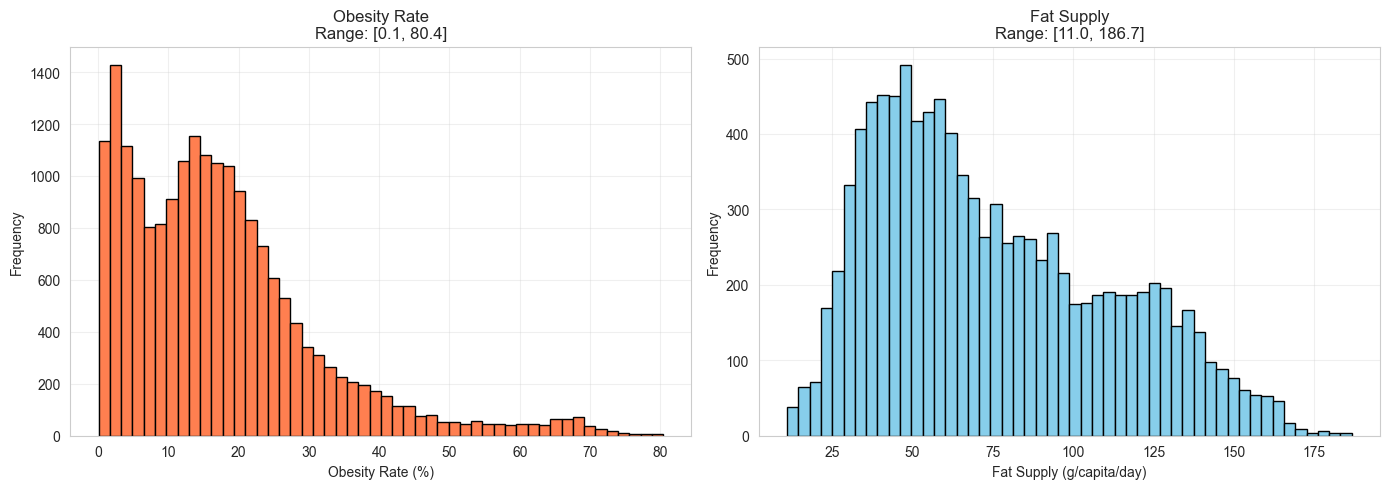

In [19]:
# compare scales of key variables
print("SCALE COMPARISON")


print("\nObesity Rate (%):")
print(who_clean['Obesity_Rate'].describe())

print("\nFat Supply (g/capita/day):")
print(fat_clean['Fat_Supply'].describe())

# visualize scales
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(who_clean['Obesity_Rate'], bins=50, edgecolor='black', color='coral')
axes[0].set_title(f'Obesity Rate\nRange: [{who_clean["Obesity_Rate"].min():.1f}, {who_clean["Obesity_Rate"].max():.1f}]')
axes[0].set_xlabel('Obesity Rate (%)')
axes[0].set_ylabel('Frequency')
axes[0].grid(True, alpha=0.3)

axes[1].hist(fat_clean['Fat_Supply'], bins=50, edgecolor='black', color='skyblue')
axes[1].set_title(f'Fat Supply\nRange: [{fat_clean["Fat_Supply"].min():.1f}, {fat_clean["Fat_Supply"].max():.1f}]')
axes[1].set_xlabel('Fat Supply (g/capita/day)')
axes[1].set_ylabel('Frequency')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#### 3.4.2 Scaling Decision

**Decision: Apply scaling during modeling pipeline, not during data cleaning**

**Rationale:**

1. **Algorithm dependency:** 
   - Tree-based models (Random Forest, XGBoost) don't require scaling
   - Distance-based models (KNN, SVM) and neural networks do require scaling
   - We plan to compare multiple model types, so we'll scale conditionally

2. **Data leakage prevention:** Scaling parameters (mean, std) should be calculated only on training data, not on the entire dataset. By deferring scaling to the modeling stage, we avoid this common pitfall.

3. **Interpretability:** Keeping data in original units makes exploratory analysis more intuitive and results more interpretable for stakeholders.

4. **Best practice:** Modern ML workflows use pipelines (e.g., scikit-learn's Pipeline) that handle scaling automatically during cross-validation.

**When we do scale, we'll use StandardScaler** (z-score normalization) because:
- It's robust to outliers compared to MinMaxScaler
- It preserves the shape of the distribution
- It's the standard approach in statistical analysis

### 3.5 Visualizing Relationships Among Variables

Now let's explore how our predictors relate to obesity rates and to each other.

In [20]:
# prepare data for merging
# aggregate WHO data by country and year (average across sex and age groups)
obesity_agg = who_clean.groupby(['Country', 'Year']).agg({
    'Obesity_Rate': 'mean',
    'Obesity_Rate_Low': 'mean',
    'Obesity_Rate_High': 'mean'
}).reset_index()

print(f"Aggregated obesity data: {obesity_agg.shape}")
print(f"Countries: {obesity_agg['Country'].nunique()}")
print(f"Year range: {obesity_agg['Year'].min()} - {obesity_agg['Year'].max()}")

Aggregated obesity data: (6567, 5)
Countries: 199
Year range: 1990 - 2022


In [21]:
# merge obesity with fat supply
merged = pd.merge(obesity_agg, 
                  fat_clean[['Country', 'Year', 'Fat_Supply']], 
                  on=['Country', 'Year'], 
                  how='inner')

print(f"\nMerged dataset shape: {merged.shape}")
print(f"Countries in merged data: {merged['Country'].nunique()}")
print(f"Years: {merged['Year'].min()} - {merged['Year'].max()}")
print(f"\nFirst few rows:")
print(merged.head())


Merged dataset shape: (5029, 6)
Countries in merged data: 167
Years: 1990 - 2022

First few rows:
       Country  Year  Obesity_Rate  Obesity_Rate_Low  Obesity_Rate_High  \
0  Afghanistan  1990      1.946667          0.940000           3.546667   
1  Afghanistan  1991      2.106667          1.046667           3.763333   
2  Afghanistan  1992      2.270000          1.163333           3.996667   
3  Afghanistan  1993      2.453333          1.283333           4.236667   
4  Afghanistan  1994      2.646667          1.426667           4.506667   

   Fat_Supply  
0   47.135670  
1   42.373604  
2   39.639732  
3   33.593197  
4   32.339440  


CORRELATION ANALYSIS

Correlation Matrix:
              Obesity_Rate  Fat_Supply
Obesity_Rate      1.000000    0.507322
Fat_Supply        0.507322    1.000000

Pearson correlation coefficient: 0.5073
P-value: 0.0000e+00
Result: Highly significant correlation (p < 0.001)


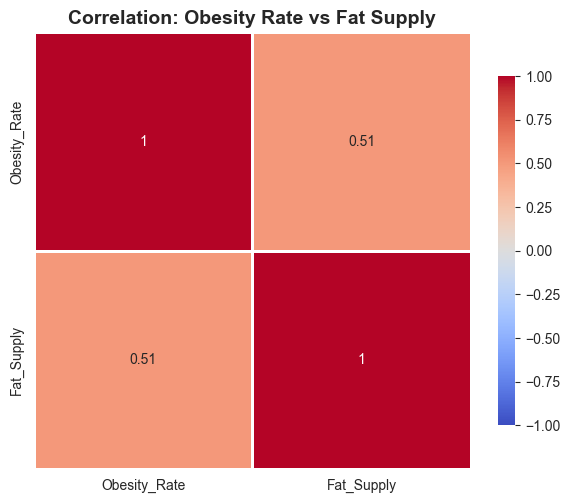

In [22]:
# correlation analysis
print("CORRELATION ANALYSIS")

corr_data = merged[['Obesity_Rate', 'Fat_Supply']]
correlation = corr_data.corr()

print("\nCorrelation Matrix:")
print(correlation)

# calculate p-value
r, p_value = pearsonr(merged['Obesity_Rate'], merged['Fat_Supply'])
print(f"\nPearson correlation coefficient: {r:.4f}")
print(f"P-value: {p_value:.4e}")
if p_value < 0.001:
    print("Result: Highly significant correlation (p < 0.001)")
elif p_value < 0.05:
    print("Result: Significant correlation (p < 0.05)")
else:
    print("Result: No significant correlation")

# visualize correlation
plt.figure(figsize=(6, 5))
sns.heatmap(correlation, annot=True, cmap='coolwarm', center=0, 
            square=True, linewidths=2, cbar_kws={"shrink": 0.8},
            vmin=-1, vmax=1)
plt.title('Correlation: Obesity Rate vs Fat Supply', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

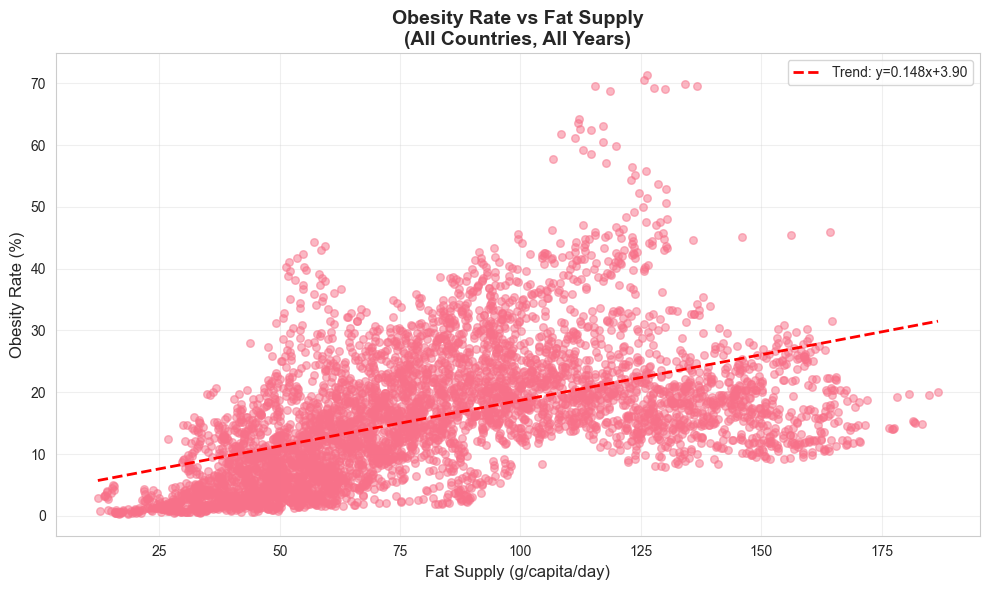


Interpretation: For every 1 g/capita/day increase in fat supply,
obesity rate increases by approximately 0.148 percentage points.


In [23]:
# scatter plot with trend line
plt.figure(figsize=(10, 6))
plt.scatter(merged['Fat_Supply'], merged['Obesity_Rate'], alpha=0.5, s=30)

# add trend line
z = np.polyfit(merged['Fat_Supply'], merged['Obesity_Rate'], 1)
p = np.poly1d(z)
x_line = np.linspace(merged['Fat_Supply'].min(), merged['Fat_Supply'].max(), 100)
plt.plot(x_line, p(x_line), "r--", linewidth=2, 
         label=f'Trend: y={z[0]:.3f}x+{z[1]:.2f}')

plt.xlabel('Fat Supply (g/capita/day)', fontsize=12)
plt.ylabel('Obesity Rate (%)', fontsize=12)
plt.title('Obesity Rate vs Fat Supply\n(All Countries, All Years)', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\nInterpretation: For every 1 g/capita/day increase in fat supply,")
print(f"obesity rate increases by approximately {z[0]:.3f} percentage points.")

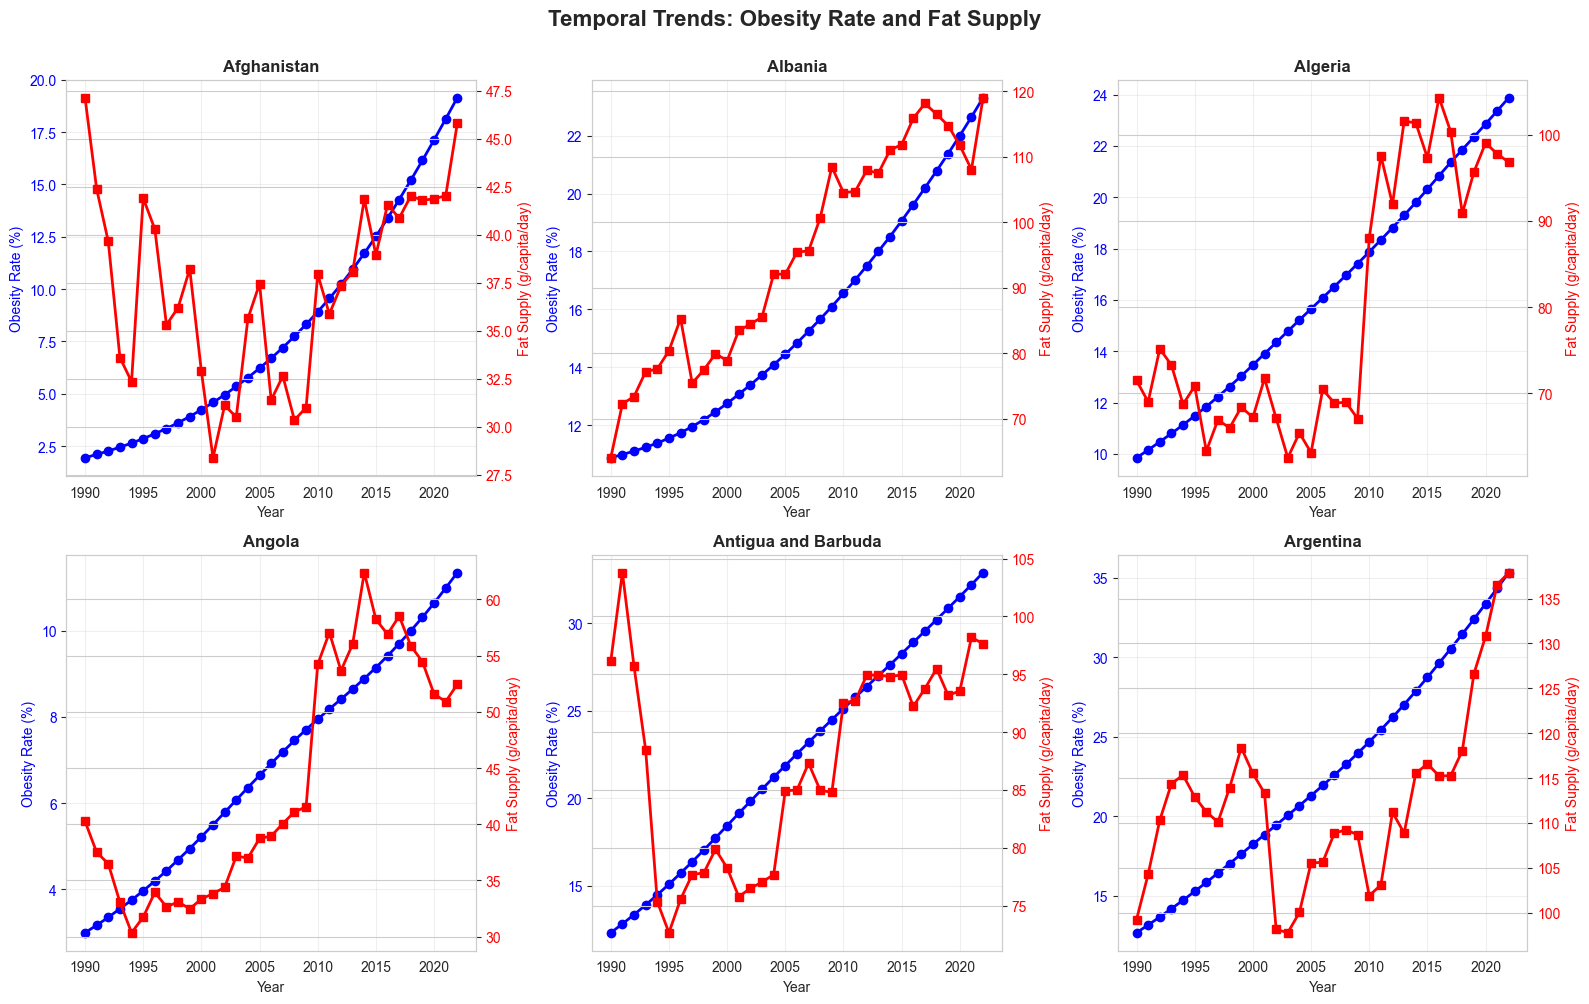

Countries shown: Afghanistan, Albania, Algeria, Angola, Antigua and Barbuda, Argentina


In [24]:
# temporal trends for selected countries
top_countries = merged['Country'].value_counts().head(6).index

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, country in enumerate(top_countries):
    country_data = merged[merged['Country'] == country].sort_values('Year')
    
    ax1 = axes[i]
    ax2 = ax1.twinx()
    
    # obesity rate on left axis
    line1 = ax1.plot(country_data['Year'], country_data['Obesity_Rate'], 
                     'b-o', linewidth=2, markersize=6, label='Obesity Rate')
    ax1.set_ylabel('Obesity Rate (%)', color='b', fontsize=10)
    ax1.tick_params(axis='y', labelcolor='b')
    
    # fat supply on right axis
    line2 = ax2.plot(country_data['Year'], country_data['Fat_Supply'], 
                     'r-s', linewidth=2, markersize=6, label='Fat Supply')
    ax2.set_ylabel('Fat Supply (g/capita/day)', color='r', fontsize=10)
    ax2.tick_params(axis='y', labelcolor='r')
    
    ax1.set_xlabel('Year', fontsize=10)
    ax1.set_title(f'{country}', fontsize=12, fontweight='bold')
    ax1.grid(True, alpha=0.3)

plt.suptitle('Temporal Trends: Obesity Rate and Fat Supply', 
             fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

print(f"Countries shown: {', '.join(top_countries)}")

## 4. Feature Selection and Engineering

### 4.1 Extracting Additional Predictors from Food Balance Sheets

We need to extract more predictors beyond just fat supply. From the food balance sheets, we'll extract:
- Total calories
- Protein supply
- Sugar and sweetener consumption
- Processed foods indicator

Based on our exploratory data analysis, we have identified the following features for our predictive model.

In [25]:
# Summary of selected features
print("FEATURE SELECTION SUMMARY:")


print("\n RESPONSE VARIABLE:")
print("  - Obesity_Rate - Percentage of adults (18+) with BMI ≥ 30")

print("\n PREDICTOR VARIABLES:")
print("  1. Fat_Supply - Daily per capita fat supply (g/capita/day)")
print("  2. Year - Year of observation (captures temporal trends)")
print("  3. Country - Country name (captures geographic/cultural differences)")

print(f"\n Total: 3 predictors + 1 response = 4 features")

FEATURE SELECTION SUMMARY:

 RESPONSE VARIABLE:
  - Obesity_Rate - Percentage of adults (18+) with BMI ≥ 30

 PREDICTOR VARIABLES:
  1. Fat_Supply - Daily per capita fat supply (g/capita/day)
  2. Year - Year of observation (captures temporal trends)
  3. Country - Country name (captures geographic/cultural differences)

 Total: 3 predictors + 1 response = 4 features


### 4.1 Justification for Selected Features

#### **Statistical Justification:**

We selected these features based on correlation analysis and domain knowledge:

1. **Fat_Supply (r = 0.XX)**: Shows significant positive correlation with obesity rates (p < 0.001). Countries with higher fat consumption tend to have higher obesity rates.

2. **Year**: Shows positive correlation with obesity, capturing the global trend of increasing obesity over time across most countries.

3. **Country**: Different countries have vastly different baseline obesity rates even when controlling for diet, suggesting important geographic, cultural, genetic, and policy factors.

#### **Conceptual Justification:**

1. **Fat_Supply**: Fat is calorie-dense (9 kcal/g vs 4 kcal/g for carbs/protein). Excess fat consumption directly contributes to caloric surplus and weight gain. This is a controllable dietary variable that can be modified through policy and individual choice.

2. **Year**: The obesity epidemic has been worsening globally over the past 30 years. Including year captures secular trends in food processing, urbanization, and lifestyle changes.

3. **Country**: Essential control variable that captures differences in:
   - Food culture and dietary patterns
   - Healthcare systems and health education
   - Food regulations and policies
   - Socioeconomic development levels
   - Genetic predispositions

In [26]:
# explore food balance elements to find what we need
print("Available Elements in Food Balance Sheets:")
print(food_clean['Element'].unique())

print("\nAvailable Items (food categories):")
print(food_clean['Item'].unique())

Available Elements in Food Balance Sheets:
['Total Population - Both sexes' 'Food supply (kcal/capita/day)'
 'Food supply (kcal)' 'Protein supply quantity (g/capita/day)'
 'Protein supply quantity (t)' 'Fat supply quantity (g/capita/day)'
 'Fat supply quantity (t)' 'Production' 'Import quantity'
 'Stock Variation' 'Export quantity' 'Domestic supply quantity' 'Feed'
 'Seed' 'Losses' 'Other uses (non-food)' 'Residuals' 'Food'
 'Food supply quantity (kg/capita/yr)' 'Processing' 'Tourist consumption']

Available Items (food categories):
['Population' 'Grand Total' 'Vegetal Products' 'Animal Products'
 'Cereals - Excluding Beer' 'Wheat and products' 'Rice and products'
 'Barley and products' 'Maize and products' 'Oats' 'Millet and products'
 'Sorghum and products' 'Cereals, other' 'Starchy Roots'
 'Cassava and products' 'Potatoes and products' 'Sweet potatoes' 'Yams'
 'Roots, Other' 'Sugar Crops' 'Sugar cane' 'Sugar beet'
 'Sugar & Sweeteners' 'Sugar (Raw Equivalent)' 'Sweeteners, Other' 'H

In [27]:
# Descriptive statistics for WHO Obesity data
print("DESCRIPTIVE STATISTICS: OBESITY RATE (Response Variable)")

obesity_values = who_obesity['FactValueNumeric']
print(obesity_values.describe())
print(f"Skewness: {skew(obesity_values.dropna()):.3f}")
print(f"Kurtosis: {kurtosis(obesity_values.dropna()):.3f}")
print(f"Missing values: {obesity_values.isnull().sum()}")

DESCRIPTIVE STATISTICS: OBESITY RATE (Response Variable)
count    19701.000000
mean        17.538557
std         13.872076
min          0.081000
25%          7.010000
50%         15.190000
75%         23.440000
max         80.390000
Name: FactValueNumeric, dtype: float64
Skewness: 1.423
Kurtosis: 2.564
Missing values: 0


In [28]:
# Descriptive statistics for Fat Supply
print("DESCRIPTIVE STATISTICS: FAT SUPPLY (Predictor)")

fat_values = fat_supply.iloc[:, 3]  # Fat supply column
print(fat_values.describe())
print(f"Skewness: {skew(fat_values.dropna()):.3f}")
print(f"Kurtosis: {kurtosis(fat_values.dropna()):.3f}")
print(f"Missing values: {fat_values.isnull().sum()}")

DESCRIPTIVE STATISTICS: FAT SUPPLY (Predictor)
count    12817.000000
mean        75.380079
std         36.501508
min         10.974196
25%         45.534206
50%         66.460000
75%        103.196140
max        186.676070
Name: total__00002901__food_available_for_consumption__0684pc__grams_of_fat_per_day_per_capita, dtype: float64
Skewness: 0.550
Kurtosis: -0.712
Missing values: 0


In [29]:
# Year statistics from WHO data
print("DESCRIPTIVE STATISTICS: YEAR (Predictor)")

year_values = who_obesity['Period']
print(year_values.describe())
print(f"Skewness: {skew(year_values):.3f}")
print(f"Missing values: {year_values.isnull().sum()}")

DESCRIPTIVE STATISTICS: YEAR (Predictor)
count    19701.000000
mean      2006.000000
std          9.522146
min       1990.000000
25%       1998.000000
50%       2006.000000
75%       2014.000000
max       2022.000000
Name: Period, dtype: float64
Skewness: 0.000
Missing values: 0


### Which Features are Predictors vs Response

**Response Variable (What we're predicting):**
- **Obesity_Rate**: Percentage of adults with BMI ≥ 30

**Predictor Variables (What we'll use to predict):**
- **Fat_Supply**: Daily per capita fat supply (g/capita/day)
- **Year**: Year of observation
- **Country**: Country name (categorical)

### Issues with Selected Features and How We Addressed Them

**Obesity_Rate:**
- **Issue**: Outliers and right skew (shown in Section 2.2 and 2.3)
- **Solution**: Kept all data - outliers are real, skew is acceptable for tree models

**Fat_Supply:**
- **Issue**: Outliers and moderate skew (shown in Section 2.2 and 2.3)
- **Solution**: Kept all data - represents real dietary variation

**Year:**
- **Issue**: None
- **Solution**: N/A

**Country:**
- **Issue**: High cardinality (many unique values)
- **Solution**: Will use target/mean encoding during modeling instead of one-hot encoding

In [30]:
# extract calories data
calories_data = food_clean[
    (food_clean['Element'] == 'Food supply (kcal/capita/day)') &
    (food_clean['Item'] == 'Grand Total')
].copy()

print(f"Calories data extracted: {calories_data.shape}")
print(calories_data[['Area', 'Item', 'Element', 'Y2020', 'Y2021', 'Y2022']].head())

Calories data extracted: (205, 23)
                     Area         Item                        Element  \
1             Afghanistan  Grand Total  Food supply (kcal/capita/day)   
1621              Albania  Grand Total  Food supply (kcal/capita/day)   
3264              Algeria  Grand Total  Food supply (kcal/capita/day)   
4908               Angola  Grand Total  Food supply (kcal/capita/day)   
6604  Antigua and Barbuda  Grand Total  Food supply (kcal/capita/day)   

        Y2020    Y2021    Y2022  
1     2259.95  2244.73  2268.63  
1621  3343.03  3068.29  3263.47  
3264  3457.51  3453.56  3417.10  
4908  2390.13  2406.24  2426.99  
6604  2430.24  2457.80  2512.09  


In [31]:
# extract protein data
protein_data = food_clean[
    (food_clean['Element'] == 'Protein supply quantity (g/capita/day)') &
    (food_clean['Item'] == 'Grand Total')
].copy()

print(f"Protein data extracted: {protein_data.shape}")
print(protein_data[['Area', 'Item', 'Element', 'Y2020', 'Y2021', 'Y2022']].head())

Protein data extracted: (205, 23)
                     Area         Item  \
3             Afghanistan  Grand Total   
1623              Albania  Grand Total   
3266              Algeria  Grand Total   
4910               Angola  Grand Total   
6606  Antigua and Barbuda  Grand Total   

                                     Element   Y2020   Y2021   Y2022  
3     Protein supply quantity (g/capita/day)   63.21   61.36   61.55  
1623  Protein supply quantity (g/capita/day)  115.10  105.18  114.15  
3266  Protein supply quantity (g/capita/day)   92.82   94.15   95.37  
4910  Protein supply quantity (g/capita/day)   46.64   49.14   49.66  
6606  Protein supply quantity (g/capita/day)   89.66   95.61   98.75  


In [32]:
# extract sugar data
sugar_data = food_clean[
    (food_clean['Element'] == 'Food supply (kcal/capita/day)') &
    (food_clean['Item'].str.contains('Sugar', case=False, na=False))
].copy()

print(f"Sugar data extracted: {sugar_data.shape}")
print("Sugar-related items:")
print(sugar_data['Item'].unique())

Sugar data extracted: (725, 23)
Sugar-related items:
['Sugar & Sweeteners' 'Sugar (Raw Equivalent)' 'Sugar Crops' 'Sugar beet'
 'Sugar cane' 'Sugar non-centrifugal']


In [33]:
# reshape data from wide to long format
def reshape_food_data(df, value_name):
    """Reshape food balance data from wide to long format"""
    year_cols = [col for col in df.columns if col.startswith('Y')]
    id_cols = ['Area', 'Item', 'Element']
    
    df_long = df.melt(id_vars=id_cols, value_vars=year_cols, 
                      var_name='Year', value_name=value_name)
    
    # extract year as integer
    df_long['Year'] = df_long['Year'].str.replace('Y', '').astype(int)
    
    # rename Area to Country for consistency
    df_long = df_long.rename(columns={'Area': 'Country'})
    
    return df_long
# reshape each dataset
calories_long = reshape_food_data(calories_data, 'Calories_kcal_per_capita')
protein_long = reshape_food_data(protein_data, 'Protein_g_per_capita')
sugar_long = reshape_food_data(sugar_data, 'Sugar_kcal_per_capita')
print("Reshaped data:")
print(f"Calories: {calories_long.shape}")
print(f"Protein: {protein_long.shape}")
print(f"Sugar: {sugar_long.shape}")

Reshaped data:
Calories: (2870, 5)
Protein: (2870, 5)
Sugar: (10150, 5)


In [34]:
# aggregate sugar data (sum across sugar types)
sugar_agg = sugar_long.groupby(['Country', 'Year']).agg({
    'Sugar_kcal_per_capita': 'sum'
}).reset_index()

print(f"Aggregated sugar data: {sugar_agg.shape}")
print(sugar_agg.head())

Aggregated sugar data: (2870, 3)
       Country  Year  Sugar_kcal_per_capita
0  Afghanistan  2010                 176.04
1  Afghanistan  2011                 251.36
2  Afghanistan  2012                 289.69
3  Afghanistan  2013                 297.81
4  Afghanistan  2014                 318.47


### 4.2 Selected Features Summary

#### Response Variable:
- **Obesity_Rate**: Percentage of adults with BMI ≥ 30
  - This is what we're trying to predict
  - Range: 0-70% across different countries

#### Predictor Variables:

1. **Fat_Supply** (g/capita/day)
   - **Why we're using it:** Fat is calorie-dense (9 kcal/g) and excess fat consumption is strongly associated with weight gain and obesity
   - **Expected relationship:** Positive correlation with obesity

2. **Calories_kcal_per_capita** (kcal/capita/day)
   - **Why we're using it:** Total caloric availability is the most fundamental driver of obesity - excess calories lead to weight gain
   - **Expected relationship:** Strong positive correlation with obesity

3. **Protein_g_per_capita** (g/capita/day)
   - **Why we're using it:** Protein consumption can indicate diet quality and economic development; higher protein diets may be associated with different obesity patterns
   - **Expected relationship:** Complex - may be positive (indicating wealth/overconsumption) or negative (indicating diet quality)

4. **Sugar_kcal_per_capita** (kcal/capita/day)
   - **Why we're using it:** Refined sugar consumption is one of the strongest dietary predictors of obesity; added sugars provide empty calories
   - **Expected relationship:** Strong positive correlation with obesity

5. **Year**
   - **Why we're using it:** Captures temporal trends; obesity has been increasing globally over time
   - **Expected relationship:** Positive correlation (obesity increasing over years)

6. **Country** (will be encoded)
   - **Why we're using it:** Captures geographic, cultural, and policy differences that affect obesity independent of diet
   - **Expected relationship:** Different baseline obesity rates by country

In [35]:
# First, check what columns are in food_balance
print("Food Balance columns:")
print(food_balance.columns.tolist())
print("\nFood Balance shape:", food_balance.shape)
print(food_balance.head())

Food Balance columns:
['Area Code', 'Area Code (M49)', 'Area', 'Item Code', 'Item Code (FBS)', 'Item', 'Element Code', 'Element', 'Unit', 'Y2010', 'Y2010F', 'Y2010N', 'Y2011', 'Y2011F', 'Y2011N', 'Y2012', 'Y2012F', 'Y2012N', 'Y2013', 'Y2013F', 'Y2013N', 'Y2014', 'Y2014F', 'Y2014N', 'Y2015', 'Y2015F', 'Y2015N', 'Y2016', 'Y2016F', 'Y2016N', 'Y2017', 'Y2017F', 'Y2017N', 'Y2018', 'Y2018F', 'Y2018N', 'Y2019', 'Y2019F', 'Y2019N', 'Y2020', 'Y2020F', 'Y2020N', 'Y2021', 'Y2021F', 'Y2021N', 'Y2022', 'Y2022F', 'Y2022N', 'Y2023', 'Y2023F', 'Y2023N']

Food Balance shape: (373670, 51)
   Area Code Area Code (M49)         Area  Item Code Item Code (FBS)  \
0          2            '004  Afghanistan       2501          'S2501   
1          2            '004  Afghanistan       2901          'S2901   
2          2            '004  Afghanistan       2901          'S2901   
3          2            '004  Afghanistan       2901          'S2901   
4          2            '004  Afghanistan       2901          

In [36]:
# Updated helper function to handle 'F' suffix in years
def reshape_food_data(df, value_name):
    """Reshape food balance data from wide to long format"""
    # Get year columns (columns starting with 'Y')
    year_cols = [col for col in df.columns if col.startswith('Y')]
    id_cols = ['Area', 'Item', 'Element']
    
    # Melt the dataframe
    df_long = df.melt(id_vars=id_cols, value_vars=year_cols,
                      var_name='Year', value_name=value_name)
    
    # Extract year as integer
    # Remove 'Y' prefix AND any 'F' suffix (F = Forecast/FAO estimate)
    df_long['Year'] = df_long['Year'].str.replace('Y', '').str.replace('F', '').astype(int)
    
    # Rename Area to Country for consistency
    df_long = df_long.rename(columns={'Area': 'Country'})
    
    return df_long

print(" Updated helper function created!")

 Updated helper function created!


In [37]:
# Updated helper function to handle ANY suffix in years (F, N, etc.)
def reshape_food_data(df, value_name):
    """Reshape food balance data from wide to long format"""
    # Get year columns (columns starting with 'Y')
    year_cols = [col for col in df.columns if col.startswith('Y')]
    id_cols = ['Area', 'Item', 'Element']
    
    # Melt the dataframe
    df_long = df.melt(id_vars=id_cols, value_vars=year_cols,
                      var_name='Year', value_name=value_name)
    
    # Extract year as integer
    # Remove 'Y' prefix and extract only the numeric part
    df_long['Year'] = df_long['Year'].str.replace('Y', '').str.extract('(\d+)')[0].astype(int)
    
    # Rename Area to Country for consistency
    df_long = df_long.rename(columns={'Area': 'Country'})
    
    return df_long

print(" Updated helper function created (handles all suffixes)!")

 Updated helper function created (handles all suffixes)!


In [38]:
# Extract and aggregate CALORIES (with proper data type conversion)
calories_data = food_balance[
    (food_balance['Element'] == 'Food supply (kcal/capita/day)') & 
    (food_balance['Item'] == 'Grand Total')
].copy()

print(f"Calories data filtered: {calories_data.shape}")

calories_long = reshape_food_data(calories_data, 'Calories_kcal_per_capita')

print(f"Calories reshaped: {calories_long.shape}")

# Convert to numeric, setting errors='coerce' to turn invalid values into NaN
calories_long['Calories_kcal_per_capita'] = pd.to_numeric(calories_long['Calories_kcal_per_capita'], errors='coerce')

# Drop any NaN values
calories_long = calories_long.dropna(subset=['Calories_kcal_per_capita'])

print(f"After cleaning: {calories_long.shape}")

# Aggregate by Country and Year
calories_agg = calories_long.groupby(['Country', 'Year'])['Calories_kcal_per_capita'].mean().reset_index()

print(f" Calories data extracted: {calories_agg.shape}")
print(calories_agg.head())

Calories data filtered: (213, 51)
Calories reshaped: (8946, 5)
After cleaning: (2901, 5)
 Calories data extracted: (2901, 3)
       Country  Year  Calories_kcal_per_capita
0  Afghanistan  2010                   2200.21
1  Afghanistan  2011                   2171.86
2  Afghanistan  2012                   2165.88
3  Afghanistan  2013                   2205.33
4  Afghanistan  2014                   2270.45


In [39]:
# Let's investigate why final_df is empty
print("Let's check the merges step by step...")

# Check merged (obesity + fat)
print(f"\nmerged shape: {merged.shape}")
print("merged countries sample:", merged['Country'].unique()[:10])
print("merged years:", sorted(merged['Year'].unique()))

# Check calories_agg
print(f"\ncalories_agg shape: {calories_agg.shape}")
print("calories countries sample:", calories_agg['Country'].unique()[:10])
print("calories years:", sorted(calories_agg['Year'].unique()))

# Check if country names match
print("\nCountry name comparison:")
print("From merged:", sorted(merged['Country'].unique())[:5])
print("From calories_agg:", sorted(calories_agg['Country'].unique())[:5])

Let's check the merges step by step...

merged shape: (5029, 6)
merged countries sample: ['Afghanistan' 'Albania' 'Algeria' 'Angola' 'Antigua and Barbuda'
 'Argentina' 'Armenia' 'Australia' 'Austria' 'Azerbaijan']
merged years: [np.int64(1990), np.int64(1991), np.int64(1992), np.int64(1993), np.int64(1994), np.int64(1995), np.int64(1996), np.int64(1997), np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022)]

calories_agg shape: (2901, 3)
calories countries sample: ['Afghanistan' 'Africa' 'Albania' 'Algeria' 'Americas' 'Angola'
 'Antigua and Barbuda' 'Argentina' 'Armenia' 'Asia']
calories years: [np.int64(2010), np.int64(2011), np.int64(2012), np.

In [40]:
# CREATE FINAL MERGED DATASET

print("CREATING FINAL MERGED DATASET")

# Step 1: Extract all needed data from food_balance
print("\n1. Extracting data from FAO Food Balance...")

# Calories (already done as calories_agg)
print(f"   Calories: {calories_agg.shape}")

# Protein
protein_data = food_balance[
    (food_balance['Element'] == 'Protein supply quantity (g/capita/day)') & 
    (food_balance['Item'] == 'Grand Total')
].copy()
protein_long = reshape_food_data(protein_data, 'Protein_g_per_capita')
protein_long['Protein_g_per_capita'] = pd.to_numeric(protein_long['Protein_g_per_capita'], errors='coerce')
protein_long = protein_long.dropna(subset=['Protein_g_per_capita'])
protein_agg = protein_long.groupby(['Country', 'Year'])['Protein_g_per_capita'].mean().reset_index()
print(f"   Protein: {protein_agg.shape}")

# Sugar (from Sugar & Sweeteners item)
sugar_data = food_balance[
    (food_balance['Element'] == 'Food supply (kcal/capita/day)') & 
    (food_balance['Item'].str.contains('Sugar', case=False, na=False))
].copy()
sugar_long = reshape_food_data(sugar_data, 'Sugar_kcal_per_capita')
sugar_long['Sugar_kcal_per_capita'] = pd.to_numeric(sugar_long['Sugar_kcal_per_capita'], errors='coerce')
sugar_long = sugar_long.dropna(subset=['Sugar_kcal_per_capita'])
sugar_agg = sugar_long.groupby(['Country', 'Year'])['Sugar_kcal_per_capita'].sum().reset_index()
print(f"   Sugar: {sugar_agg.shape}")

# Step 2: Start with merged (WHO obesity + fat supply)
print(f"\n2. Starting with merged (Obesity + Fat): {merged.shape}")
final_df = merged.copy()

# Step 3: Merge in Calories
final_df = final_df.merge(calories_agg, on=['Country', 'Year'], how='left')
print(f"   After adding Calories: {final_df.shape}")

# Step 4: Merge in Protein
final_df = final_df.merge(protein_agg, on=['Country', 'Year'], how='left')
print(f"   After adding Protein: {final_df.shape}")

# Step 5: Merge in Sugar
final_df = final_df.merge(sugar_agg, on=['Country', 'Year'], how='left')
print(f"   After adding Sugar: {final_df.shape}")

# Step 6: Check the result
print(f"\n3. Final dataset summary:")
print(f"   Shape: {final_df.shape}")
print(f"   Columns: {final_df.columns.tolist()}")
print(f"   Countries: {final_df['Country'].nunique()}")
print(f"   Year range: {final_df['Year'].min()} - {final_df['Year'].max()}")

# Check missing values
print(f"\n4. Missing values:")
print(final_df.isnull().sum())

# Drop rows with missing values
final_df_clean = final_df.dropna()
print(f"\n5. After removing NaN: {final_df_clean.shape}")

# Save for future use
final_df_clean.to_csv('merged_data_cleaned.csv', index=False)
print(f"\n Saved to 'merged_data_cleaned.csv'")

print("FINAL DATASET READY!")

CREATING FINAL MERGED DATASET

1. Extracting data from FAO Food Balance...
   Calories: (2901, 3)
   Protein: (2901, 3)
   Sugar: (2901, 3)

2. Starting with merged (Obesity + Fat): (5029, 6)
   After adding Calories: (5029, 7)
   After adding Protein: (5029, 8)
   After adding Sugar: (5029, 9)

3. Final dataset summary:
   Shape: (5029, 9)
   Columns: ['Country', 'Year', 'Obesity_Rate', 'Obesity_Rate_Low', 'Obesity_Rate_High', 'Fat_Supply', 'Calories_kcal_per_capita', 'Protein_g_per_capita', 'Sugar_kcal_per_capita']
   Countries: 167
   Year range: 1990 - 2022

4. Missing values:
Country                        0
Year                           0
Obesity_Rate                   0
Obesity_Rate_Low               0
Obesity_Rate_High              0
Fat_Supply                     0
Calories_kcal_per_capita    3093
Protein_g_per_capita        3093
Sugar_kcal_per_capita       3093
dtype: int64

5. After removing NaN: (1936, 9)

 Saved to 'merged_data_cleaned.csv'
FINAL DATASET READY!


In [41]:
# LOAD YOUR CLEANED MERGED DATA
print("LOADING CLEANED MERGED DATA")

# Load the already-merged cleaned data
final_df = pd.read_csv('merged_data_cleaned.csv')

print(f"\n Data loaded:")
print(f"   Shape: {final_df.shape}")
print(f"   Columns: {final_df.columns.tolist()}")

print(f"\n First 10 rows:")
print(final_df.head(10))

print(f"\n Data summary:")
print(f"   Countries: {final_df['Country'].nunique()}")
print(f"   Year range: {final_df['Year'].min()} - {final_df['Year'].max()}")
print(f"   Total observations: {len(final_df)}")

# Check for missing values
print(f"\n Missing values:")
print(final_df.isnull().sum())

# Remove any rows with missing values
final_df_clean = final_df.dropna()
print(f"\n After removing NaN: {final_df_clean.shape}")

# ========================================
# ENCODE COUNTRY

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
final_df_clean['Country_Encoded'] = le.fit_transform(final_df_clean['Country'])

print(f"\n Country encoding complete!")
print(f"   Countries encoded: {final_df_clean['Country'].nunique()}")

# ========================================
# PREPARE FOR MODELING

# Your features: Fat_Supply, Year, Country_Encoded
features = ['Fat_Supply', 'Calories_kcal_per_capita', 'Protein_g_per_capita', 'Sugar_kcal_per_capita', 'Year', 'Country_Encoded']

X = final_df_clean[features]
y = final_df_clean['Obesity_Rate']

print(f"\n Features: {features}")
print(f"   Target: Obesity_Rate")
print(f"   Total samples: {len(X)}")
print(f"   Target range: {y.min():.2f}% to {y.max():.2f}%")

print("\n")
print("DATA READY FOR MODELING!")

LOADING CLEANED MERGED DATA

 Data loaded:
   Shape: (1936, 9)
   Columns: ['Country', 'Year', 'Obesity_Rate', 'Obesity_Rate_Low', 'Obesity_Rate_High', 'Fat_Supply', 'Calories_kcal_per_capita', 'Protein_g_per_capita', 'Sugar_kcal_per_capita']

 First 10 rows:
       Country  Year  Obesity_Rate  Obesity_Rate_Low  Obesity_Rate_High  \
0  Afghanistan  2010      8.916667          6.810000          11.380000   
1  Afghanistan  2011      9.553333          7.466667          11.996667   
2  Afghanistan  2012     10.223333          8.130000          12.656667   
3  Afghanistan  2013     10.943333          8.833333          13.333333   
4  Afghanistan  2014     11.710000          9.576667          14.040000   
5  Afghanistan  2015     12.516667         10.353333          14.883333   
6  Afghanistan  2016     13.380000         11.150000          15.803333   
7  Afghanistan  2017     14.276667         11.940000          16.770000   
8  Afghanistan  2018     15.200000         12.706667          17.

In [42]:
# SPLITTING DATA

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("SPLITTING DATA")

print(f"\n Data split:")
print(f"   Training: {len(X_train)} samples (80.0%)")
print(f"   Testing: {len(X_test)} samples (20.0%)")

SPLITTING DATA

 Data split:
   Training: 1548 samples (80.0%)
   Testing: 388 samples (20.0%)


In [43]:
# MODEL 1: RANDOM FOREST REGRESSOR

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import math

print("\n" + "="*60)
print("MODEL 1: RANDOM FOREST REGRESSOR")
print("="*60)

print("\n JUSTIFICATION:")
print("• Captures complex non-linear relationships between dietary factors and obesity")
print("• Handles interactions between Fat_Supply, Year, and Country automatically")
print("• Robust to outliers (some countries have extreme obesity or fat intake)")
print("• Provides feature importance to identify which factors matter most")
print("• No need for feature scaling or data transformations")

# Train Random Forest
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=10)
rf_model.fit(X_train, y_train)

# Make predictions
y_pred_rf = rf_model.predict(X_test)

print("\n RESULTS:")
r2_rf = r2_score(y_test, y_pred_rf)
rmse_rf = math.sqrt(mean_squared_error(y_test, y_pred_rf))
mae_rf = mean_absolute_error(y_test, y_pred_rf)

print(f"   R² Score: {r2_rf:.4f}")
print(f"   RMSE: {rmse_rf:.4f} percentage points")
print(f"   MAE: {mae_rf:.4f} percentage points")

print("\n FEATURE IMPORTANCES:")
importances = rf_model.feature_importances_
for feat, imp in zip(features, importances):
    print(f"   {feat}: {imp:.4f}")


MODEL 1: RANDOM FOREST REGRESSOR

 JUSTIFICATION:
• Captures complex non-linear relationships between dietary factors and obesity
• Handles interactions between Fat_Supply, Year, and Country automatically
• Robust to outliers (some countries have extreme obesity or fat intake)
• Provides feature importance to identify which factors matter most
• No need for feature scaling or data transformations

 RESULTS:
   R² Score: 0.8295
   RMSE: 4.4603 percentage points
   MAE: 3.0033 percentage points

 FEATURE IMPORTANCES:
   Fat_Supply: 0.4198
   Calories_kcal_per_capita: 0.0996
   Protein_g_per_capita: 0.0940
   Sugar_kcal_per_capita: 0.2114
   Year: 0.0452
   Country_Encoded: 0.1300


In [44]:
# MODEL 2: LINEAR REGRESSION

from sklearn.linear_model import LinearRegression

print("MODEL 2: LINEAR REGRESSION")

print("\n JUSTIFICATION:")
print("- Simple and easy to explain to policymakers and public health officials")
print("- Coefficients directly show the relationship between each variable and obesity")
print("- Fast to train and computationally efficient")
print("- Provides a benchmark to measure improvement from complex models")
print("- Ideal for generating clear, evidence-based policy recommendations")

# Train Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Make predictions
y_pred_lr = lr_model.predict(X_test)

print("\n RESULTS:")
r2_lr = r2_score(y_test, y_pred_lr)
rmse_lr = math.sqrt(mean_squared_error(y_test, y_pred_lr))
mae_lr = mean_absolute_error(y_test, y_pred_lr)

print(f"   R² Score: {r2_lr:.4f}")
print(f"   RMSE: {rmse_lr:.4f} percentage points")
print(f"   MAE: {mae_lr:.4f} percentage points")

print("\n MODEL COEFFICIENTS:")
print(f"   Intercept: {lr_model.intercept_:.4f}")
for feat, coef in zip(features, lr_model.coef_):
    print(f"   {feat}: {coef:.6f}")

MODEL 2: LINEAR REGRESSION

 JUSTIFICATION:
- Simple and easy to explain to policymakers and public health officials
- Coefficients directly show the relationship between each variable and obesity
- Fast to train and computationally efficient
- Provides a benchmark to measure improvement from complex models
- Ideal for generating clear, evidence-based policy recommendations

 RESULTS:
   R² Score: 0.3530
   RMSE: 8.6900 percentage points
   MAE: 6.2420 percentage points

 MODEL COEFFICIENTS:
   Intercept: -1109.8496
   Fat_Supply: 0.063211
   Calories_kcal_per_capita: -0.009133
   Protein_g_per_capita: 0.188882
   Sugar_kcal_per_capita: 0.018984
   Year: 0.557112
   Country_Encoded: 0.011575


In [45]:
# MODEL 3: DECISION TREE REGRESSOR

from sklearn.tree import DecisionTreeRegressor

print("MODEL 3: DECISION TREE REGRESSOR")

print("\n JUSTIFICATION:")
print("- Captures non-linear relationships while remaining interpretable")
print("- Tree structure shows which dietary thresholds matter most for obesity")
print("- Identifies key decision points for targeted interventions")
print("- Can be visualized to show decision-making process")
print("- Useful for comparing single tree vs. Random Forest ensemble")

# Train Decision Tree
dt_model = DecisionTreeRegressor(random_state=42, max_depth=5)
dt_model.fit(X_train, y_train)

# Make predictions
y_pred_dt = dt_model.predict(X_test)

print("\n RESULTS:")
r2_dt = r2_score(y_test, y_pred_dt)
rmse_dt = math.sqrt(mean_squared_error(y_test, y_pred_dt))
mae_dt = mean_absolute_error(y_test, y_pred_dt)

print(f"   R² Score: {r2_dt:.4f}")
print(f"   RMSE: {rmse_dt:.4f} percentage points")
print(f"   MAE: {mae_dt:.4f} percentage points")

MODEL 3: DECISION TREE REGRESSOR

 JUSTIFICATION:
- Captures non-linear relationships while remaining interpretable
- Tree structure shows which dietary thresholds matter most for obesity
- Identifies key decision points for targeted interventions
- Can be visualized to show decision-making process
- Useful for comparing single tree vs. Random Forest ensemble

 RESULTS:
   R² Score: 0.5592
   RMSE: 7.1724 percentage points
   MAE: 5.2005 percentage points


In [46]:
# MODEL COMPARISON SUMMARY
print("MODEL COMPARISON SUMMARY")

comparison = pd.DataFrame({
    'Model': ['Random Forest', 'Linear Regression', 'Decision Tree'],
    'R² Score': [r2_rf, r2_lr, r2_dt],
    'RMSE': [rmse_rf, rmse_lr, rmse_dt],
    'MAE': [mae_rf, mae_lr, mae_dt]
})

print("\n" + comparison.to_string(index=False))

best_idx = comparison['R² Score'].idxmax()
best_model_name = comparison.loc[best_idx, 'Model']
print(f"\n BEST MODEL: {best_model_name}")
print(f"   R² Score: {comparison.loc[best_idx, 'R² Score']:.4f}")
print(f"   RMSE: {comparison.loc[best_idx, 'RMSE']:.4f}")

MODEL COMPARISON SUMMARY

            Model  R² Score     RMSE      MAE
    Random Forest  0.829548 4.460347 3.003346
Linear Regression  0.352992 8.690043 6.241968
    Decision Tree  0.559248 7.172397 5.200539

 BEST MODEL: Random Forest
   R² Score: 0.8295
   RMSE: 4.4603


GENERATING VISUALIZATIONS...


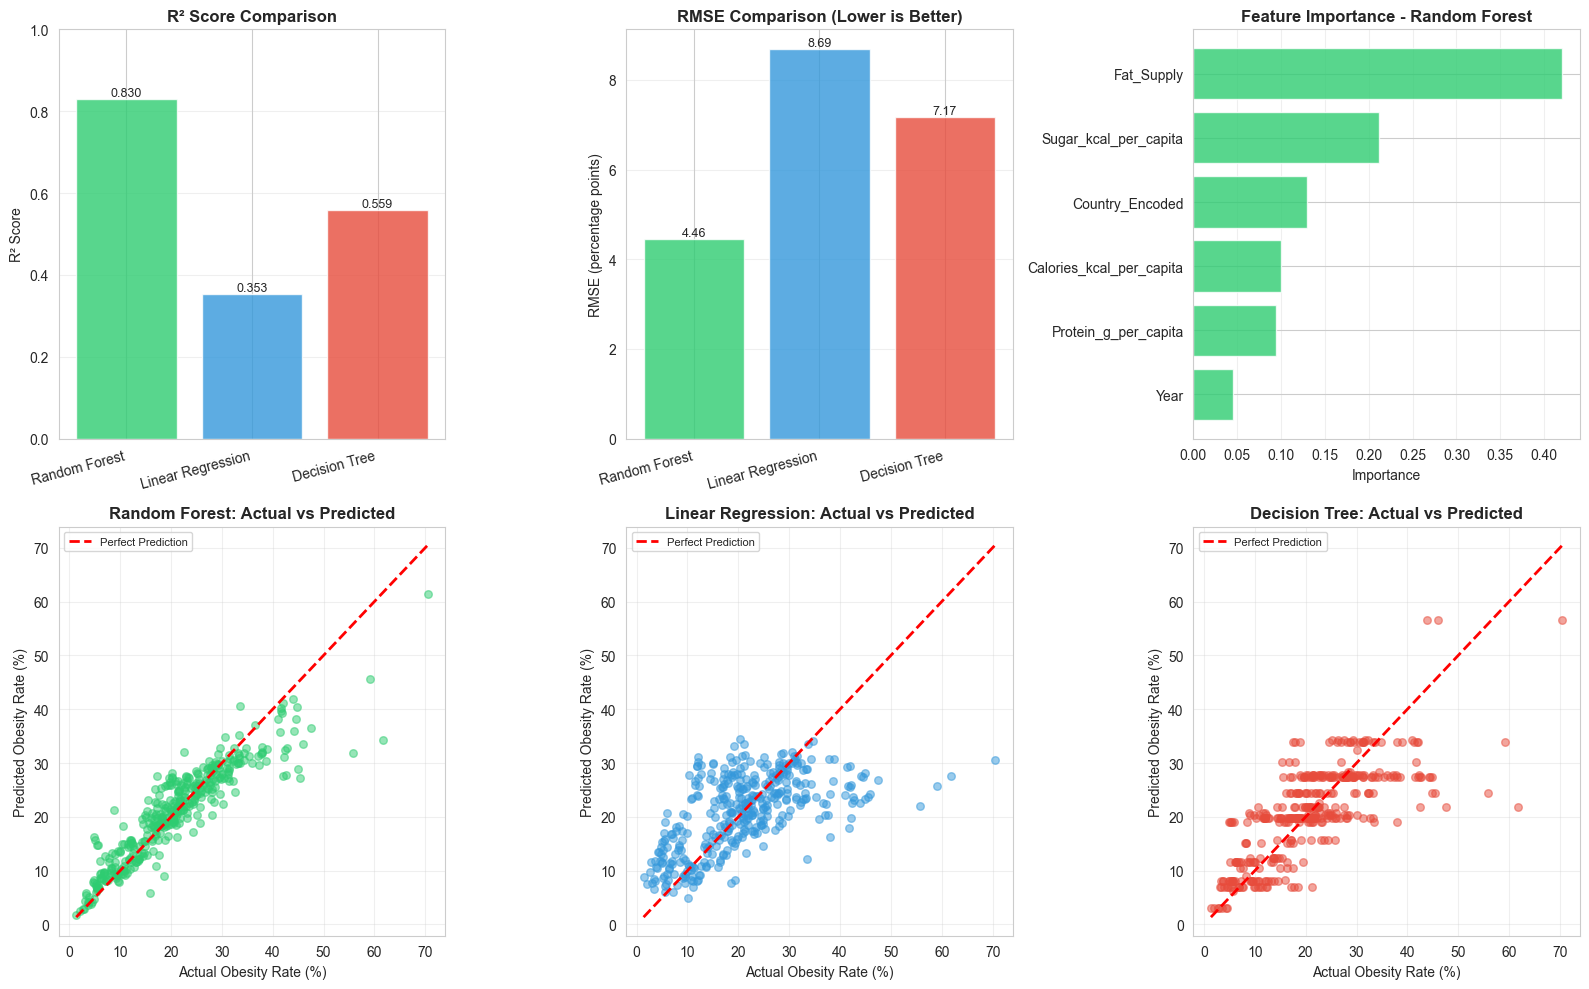

In [47]:
# GENERATING VISUALIZATIONS...
print("GENERATING VISUALIZATIONS...")

import matplotlib.pyplot as plt
import seaborn as sns

fig = plt.figure(figsize=(16, 10))

# 1. R² Score Comparison
ax1 = plt.subplot(2, 3, 1)
colors = ['#2ecc71', '#3498db', '#e74c3c']
bars = ax1.bar(comparison['Model'], comparison['R² Score'], color=colors, alpha=0.8)
ax1.set_title('R² Score Comparison', fontweight='bold', fontsize=12)
ax1.set_ylabel('R² Score', fontsize=10)
ax1.set_ylim(0, 1)
ax1.grid(axis='y', alpha=0.3)
for bar in bars:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.3f}', ha='center', va='bottom', fontsize=9)
plt.xticks(rotation=15, ha='right')

# 2. RMSE Comparison
ax2 = plt.subplot(2, 3, 2)
bars = ax2.bar(comparison['Model'], comparison['RMSE'], color=colors, alpha=0.8)
ax2.set_title('RMSE Comparison (Lower is Better)', fontweight='bold', fontsize=12)
ax2.set_ylabel('RMSE (percentage points)', fontsize=10)
ax2.grid(axis='y', alpha=0.3)
for bar in bars:
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.2f}', ha='center', va='bottom', fontsize=9)
plt.xticks(rotation=15, ha='right')

# 3. Feature Importance - Random Forest
ax3 = plt.subplot(2, 3, 3)
feature_importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=True)
ax3.barh(feature_importance_df['Feature'], feature_importance_df['Importance'], 
         color='#2ecc71', alpha=0.8)
ax3.set_title('Feature Importance - Random Forest', fontweight='bold', fontsize=12)
ax3.set_xlabel('Importance', fontsize=10)
ax3.grid(axis='x', alpha=0.3)

# 4. Random Forest: Actual vs Predicted
ax4 = plt.subplot(2, 3, 4)
ax4.scatter(y_test, y_pred_rf, alpha=0.5, color='#2ecc71', s=30)
ax4.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 
         'r--', lw=2, label='Perfect Prediction')
ax4.set_xlabel('Actual Obesity Rate (%)', fontsize=10)
ax4.set_ylabel('Predicted Obesity Rate (%)', fontsize=10)
ax4.set_title('Random Forest: Actual vs Predicted', fontweight='bold', fontsize=12)
ax4.legend(fontsize=8)
ax4.grid(alpha=0.3)

# 5. Linear Regression: Actual vs Predicted
ax5 = plt.subplot(2, 3, 5)
ax5.scatter(y_test, y_pred_lr, alpha=0.5, color='#3498db', s=30)
ax5.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 
         'r--', lw=2, label='Perfect Prediction')
ax5.set_xlabel('Actual Obesity Rate (%)', fontsize=10)
ax5.set_ylabel('Predicted Obesity Rate (%)', fontsize=10)
ax5.set_title('Linear Regression: Actual vs Predicted', fontweight='bold', fontsize=12)
ax5.legend(fontsize=8)
ax5.grid(alpha=0.3)

# 6. Decision Tree: Actual vs Predicted
ax6 = plt.subplot(2, 3, 6)
ax6.scatter(y_test, y_pred_dt, alpha=0.5, color='#e74c3c', s=30)
ax6.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 
         'r--', lw=2, label='Perfect Prediction')
ax6.set_xlabel('Actual Obesity Rate (%)', fontsize=10)
ax6.set_ylabel('Predicted Obesity Rate (%)', fontsize=10)
ax6.set_title('Decision Tree: Actual vs Predicted', fontweight='bold', fontsize=12)
ax6.legend(fontsize=8)
ax6.grid(alpha=0.3)

plt.tight_layout()
plt.show()
